<a href="https://colab.research.google.com/github/NewcomerATL/KASDD-Clustering/blob/main/TP2_B06_JMK48.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Life Expectancy Regression
## Ridge Regression Model

**Objective:** Predict `Life Expectancy` using a **regression** model evaluated by **R^2** score.

**Submission format:** `id, Life Expectancy`

## Step 1: Load Data & Imports

In [ ]:
!pip install optuna

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Regression model & utilities
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", palette="Set2")
PALETTE = {"Developed": "#4C72B0", "Developing": "#DD8452"}


In [ ]:
# Load the datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (10070, 21)
Test shape: (1259, 19)


## Step 2: Data Exploration (EDA)

In [ ]:
# Missing values analysis
missing = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(2)

missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False))


                                 Missing Count  Missing %
Population                                 527       5.23
Hepatitis B                                456       4.53
GDP                                        363       3.60
Total expenditure                          176       1.75
Alcohol                                    150       1.49
Income composition of resources            140       1.39
Schooling                                  137       1.36
thinness  1-19 years                        23       0.23
BMI                                         23       0.23
thinness 5-9 years                          23       0.23
Polio                                       13       0.13
Diphtheria                                  13       0.13
Life expectancy                              8       0.08
Adult Mortality                              8       0.08


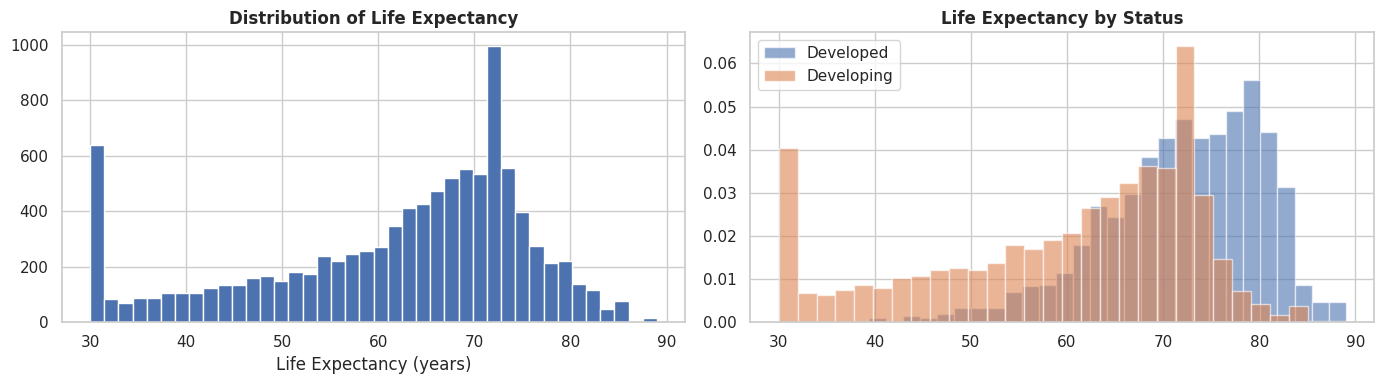

In [ ]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train["Life expectancy"].dropna(), bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution of Life Expectancy", fontweight="bold")
axes[0].set_xlabel("Life Expectancy (years)")
for label, grp in train.groupby("Status"):
    axes[1].hist(grp["Life expectancy"].dropna(), bins=30, alpha=0.6, label=label, density=True, color=PALETTE.get(label, "grey"), edgecolor="white")
axes[1].set_title("Life Expectancy by Status", fontweight="bold")
axes[1].legend()
plt.tight_layout();
plt.show()


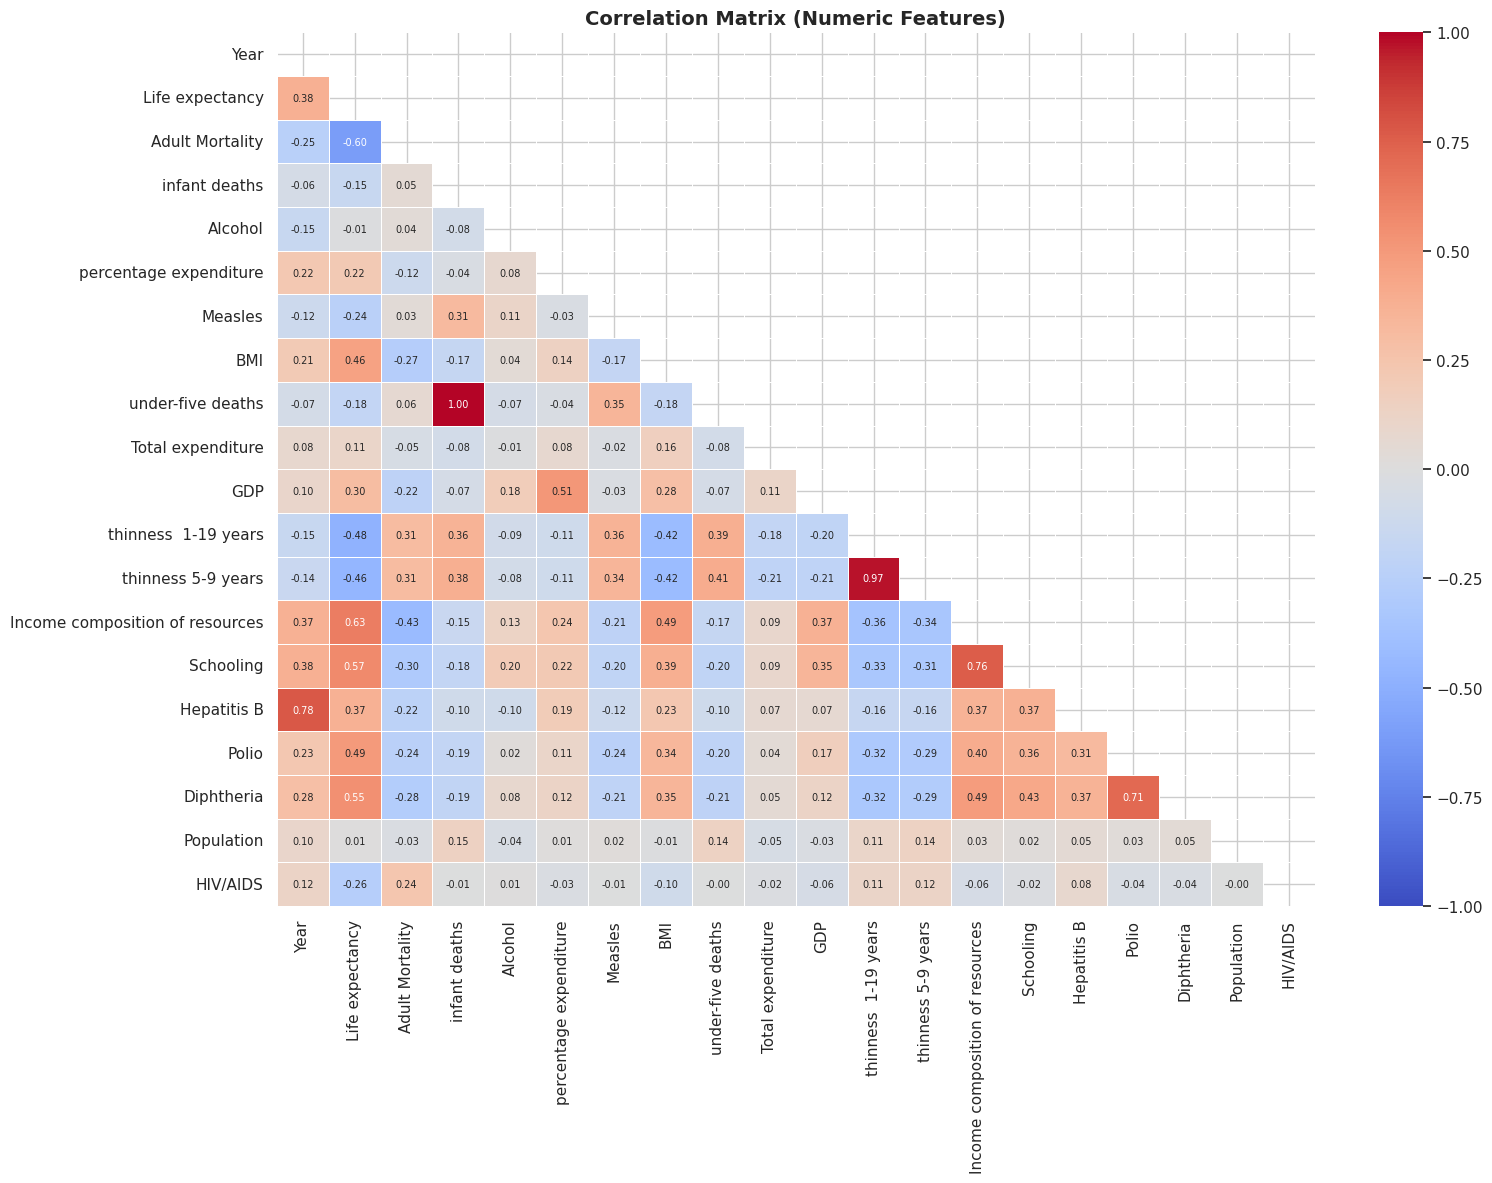

In [ ]:
# Correlation heatmap (numeric features)
num_cols = train.select_dtypes(include=np.number).columns.tolist()

fig, ax = plt.subplots(figsize=(16, 12))
corr = train[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap="coolwarm", linewidths=0.5, linecolor="white", ax=ax, annot_kws={"size": 7}, vmin=-1, vmax=1)
ax.set_title("Correlation Matrix (Numeric Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Insight

Berdasarkan graph dan correlation heatmap di atas, Population memiliki korelasi yang sangat kecil dengan Life Expectancy dan column lainnya sehingga column tersebut sebaiknya di-drop. Selain itu, positive correlation antara Polio, Diphtheria, dan Hepatitis B dengan Life Expectancy menunjukkan bahwa ketiga column tersebut menunjukkan tingkat imunisasi terhadap penyakit tersebut, bukan tingkat kematian.

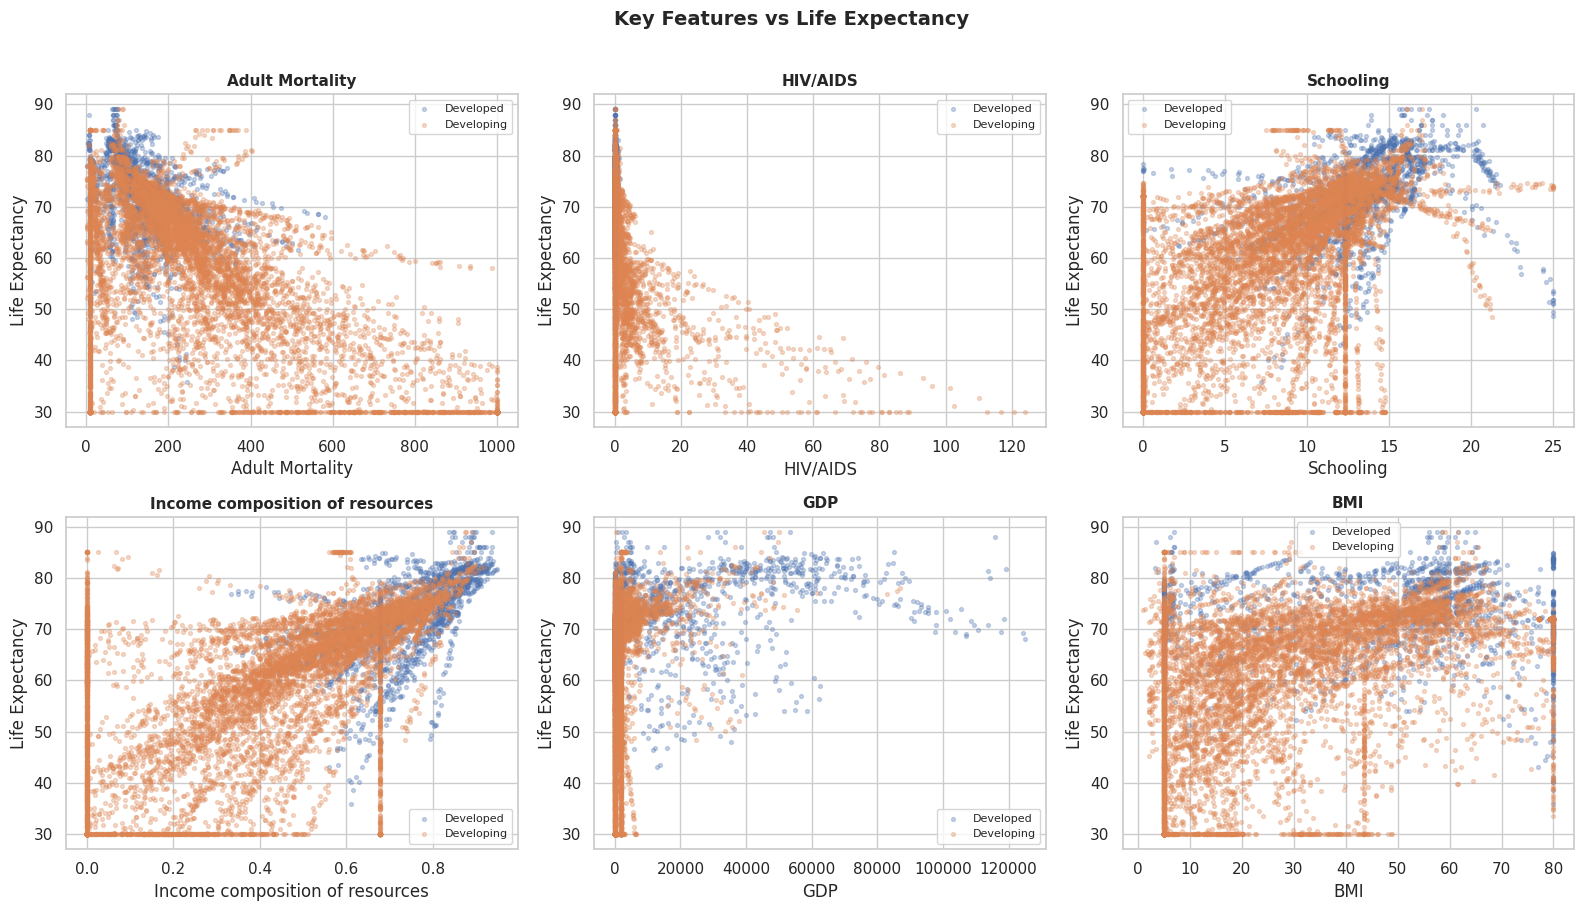

In [ ]:
# Key features vs Life Expectancy scatter plots
key_features = ["Adult Mortality", "HIV/AIDS", "Schooling","Income composition of resources", "GDP", "BMI"]
key_features = [col for col in key_features if col in train.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    for label, grp in train.groupby("Status"):
        axes[i].scatter(grp[feat], grp["Life expectancy"], alpha=0.3, s=8, label=label, color=PALETTE.get(label, "grey"))
    axes[i].set_title(feat, fontsize=11, fontweight="bold")
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel("Life Expectancy")
    axes[i].legend(fontsize=8)

plt.suptitle("Key Features vs Life Expectancy", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

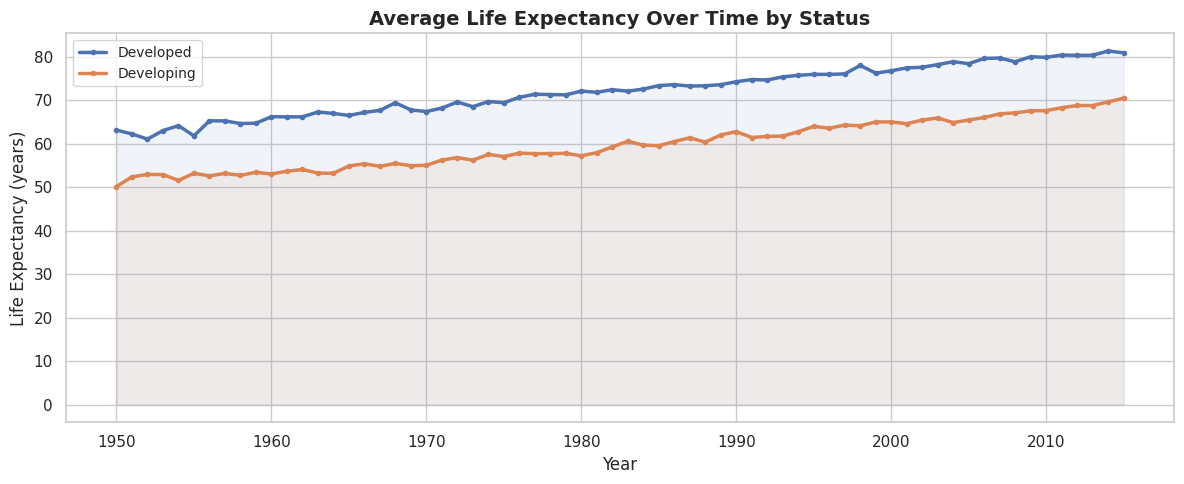

In [ ]:
# Life Expectancy trend over time
time_df = train.groupby(["Year", "Status"])["Life expectancy"].mean().reset_index()

fig, axes = plt.subplots(figsize=(12, 5))
for label, grp in time_df.groupby("Status"):
    axes.plot(grp["Year"], grp["Life expectancy"], label=label, color=PALETTE.get(label), linewidth=2.5, marker="o", markersize=3)
    axes.fill_between(grp["Year"], grp["Life expectancy"], alpha=0.08, color=PALETTE.get(label))

axes.set_title("Average Life Expectancy Over Time by Status", fontsize=14, fontweight="bold")
axes.set_xlabel("Year")
axes.set_ylabel("Life Expectancy (years)")
axes.legend(fontsize=10)
plt.tight_layout()
plt.show()

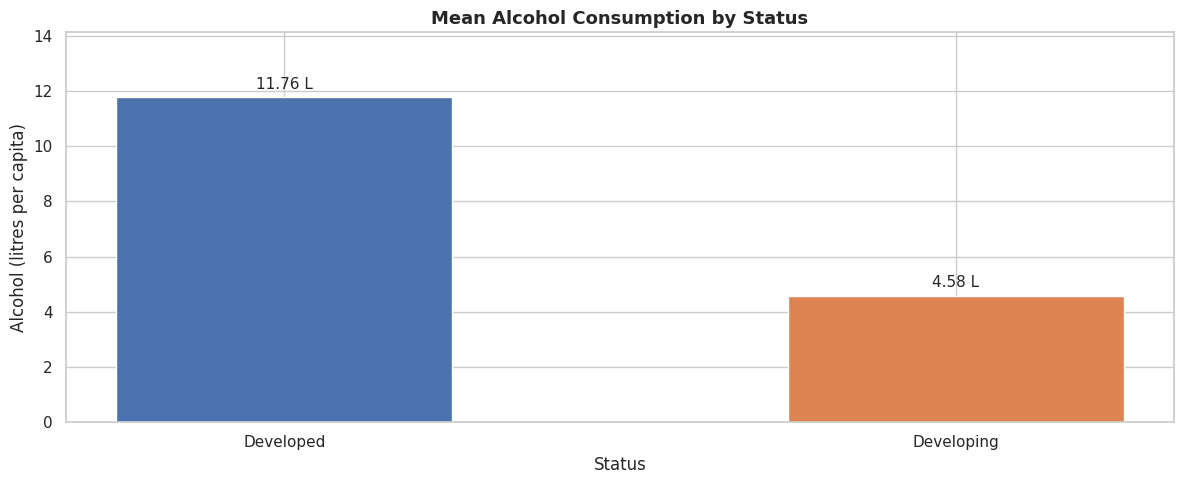

In [ ]:
# Alcohol Consumption in Developed vs Developing
time_df = train.groupby(["Year", "Status"])["Alcohol"].mean().reset_index()

fig, axes = plt.subplots(figsize=(12, 5))
bar_df = train.groupby("Status")["Alcohol"].mean().reset_index()
bar_colors = [PALETTE.get(s, "grey") for s in bar_df["Status"]]
bars = axes.bar(bar_df["Status"], bar_df["Alcohol"], color=bar_colors, edgecolor="white", width=0.5)
axes.bar_label(bars, fmt="%.2f L", padding=4, fontsize=11)
axes.set_title("Mean Alcohol Consumption by Status", fontsize=13, fontweight="bold")
axes.set_xlabel("Status")
axes.set_ylabel("Alcohol (litres per capita)")
axes.set_ylim(0, bar_df["Alcohol"].max() * 1.2)

plt.tight_layout()
plt.show()

### Insight
Berdasarkan graph di atas, dapat dilihat bahwa konsumsi Alcohol di negara Developed lebih dari dua kali lipat konsumsi Alcohol di negara Developing, tetapi, berdasarkan graph sebelumnya yang menunjukkan trend Life Expectancy di negara Developed dan Developing, Life Expectancy di negara Developed lebih tinggi daripada Life Expectancy di negara Developing. Hal tersebut mengimplikasi bahwa teknologi kesehatan di negara Developed lebih maju sehingga Life Expectancy tetap tinggi meskipun tingkat konsumsi Alcohol tinggi.

In [ ]:
# Check for skweness
skew = train.select_dtypes(include=np.number).skew().sort_values(ascending=False)

# Flag: |skew| > 1 = moderate, |skew| > 2 = severe
def flag(s):
    if abs(s) > 2:
        return "severe"
    elif abs(s) > 1:
        return "moderate"
    else:
        return "ok"

skew_df = pd.DataFrame({
    "skewness": skew.round(3),
    "abs_skew": skew.abs().round(3),
    "flag": skew.apply(flag),
    "fix": skew.apply(lambda s: "log1p" if abs(s) > 1 else "�")
})

print(skew_df.sort_values("abs_skew", ascending=False).to_string())

                                 skewness  abs_skew      flag    fix
Population                         26.781    26.781    severe  log1p
infant deaths                      12.439    12.439    severe  log1p
under-five deaths                  12.311    12.311    severe  log1p
Measles                            10.467    10.467    severe  log1p
percentage expenditure              9.759     9.759    severe  log1p
HIV/AIDS                            8.171     8.171    severe  log1p
GDP                                 4.718     4.718    severe  log1p
thinness 5-9 years                  2.394     2.394    severe  log1p
thinness  1-19 years                2.392     2.392    severe  log1p
Adult Mortality                     1.654     1.654  moderate  log1p
Alcohol                             1.415     1.415  moderate  log1p
Total expenditure                   1.227     1.227  moderate  log1p
Polio                              -1.072     1.072  moderate  log1p
Diphtheria                        

## Step 3: Data Cleaning

In [ ]:
# Clips outliers
def clip_outliers(df, exclude_cols=None):
    df = df.copy()
    exclude_cols = exclude_cols or []
    cols = [c for c in df.select_dtypes(include=np.number).columns if c not in exclude_cols]
    for col in cols:
        Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        IQR = Q3 - Q1
        df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
    return df

cols_to_skip = ["Year", "Life expectancy", "Adult Mortality", "HIV/AIDS"]
train_clipped = clip_outliers(train, exclude_cols=cols_to_skip)
test_clipped = clip_outliers(test,  exclude_cols=[c for c in cols_to_skip if c != "Life expectancy"])


In [ ]:
# Replace pre-1982 Hepatitis B zeros with NaN (disease wasn't tested for yet)
def fill_pre1982_hepatitis(train_df, test_df):
    train_df, test_df = train_df.copy(), test_df.copy()
    for df in [train_df, test_df]:
        mask = (df["Year"] < 1982) & (df["Hepatitis B"] == 0)
        df.loc[mask, "Hepatitis B"] = np.nan
    return train_df, test_df

train_cleaned, test_cleaned = fill_pre1982_hepatitis(train_clipped, test_clipped)
train_cleaned = train_cleaned.loc[~train_cleaned["Life expectancy"].isna()].reset_index(drop=True)
print(f"Train shape after cleaning: {train_cleaned.shape}")


Train shape after cleaning: (10062, 21)


## Step 4: Feature Engineering

In [ ]:
def engineer_features(df):
    df = df.copy()

    # Encode Status as binary
    if "Status" in df.columns:
        df["is_developing"] = (df["Status"] == "Developing").astype(int)
        df.drop(columns=["Status"], inplace=True)

    # Drop infant deaths (subset of under-five deaths)
    if "infant deaths" in df.columns:
        df.drop(columns=["infant deaths"], inplace=True)

    # Average immunisation coverage
    if "Polio" in df.columns and "Diphtheria" in df.columns:
        df["avg_immunisation"] = (df["Polio"] + df["Diphtheria"]) / 2

    # Schooling x Income composition interaction
    if "Schooling" in df.columns and "Income composition of resources" in df.columns:
        df["schooling_x_income"] = df["Schooling"] * df["Income composition of resources"]

    # GDP x Income composition interaction
    if "GDP" in df.columns and "Income composition of resources" in df.columns:
        df["gdp_x_income"] = df["GDP"] * df["Income composition of resources"]

    # Alcohol x Development interaction
    if "Alcohol" in df.columns and "is_developing" in df.columns:
        df["alcohol_x_development"] = df["Alcohol"] * df["is_developing"]

    # Adult Mortality and nutrition interaction
    if "Adult Mortality" in df.columns and "thinness 1-19 years" in df.columns:
        df["mortality_x_thinness"] = df["Adult Mortality"] * df["thinness 1-19 years"]
    if 'Adult Mortality' in df.columns and 'BMI' in df.columns:
        df['mortality_x_bmi'] = df['Adult Mortality'] * df['BMI']

    # Disease burden interaction
    if "HIV/AIDS" in df.columns:
        df["log_hiv"] = np.log1p(df["HIV/AIDS"].clip(0))
    if "Adult Mortality" in df.columns and "log_hiv" in df.columns:
        df["disease_burden"] = df["Adult Mortality"] * df["log_hiv"]
    if 'log_hiv' in df.columns and 'is_developing' in df.columns:
        df['hiv_x_developing'] = df['log_hiv'] * df['is_developing']

    # Square non-linear features
    for raw_col, new_col in [
        ("Adult Mortality", "adult_mortality_sq"),
        ("Schooling", "schooling_sq"),
        ("Income composition of resources", "income_sq"),
        ("BMI", "bmi_sq"),
    ]:
        if raw_col in df.columns:
            df[new_col] = df[raw_col] ** 2

    # Log-transform skewed features
    for raw_col, new_col in [
        ("under-five deaths", "log_under_five_deaths"),
        ("Measles", "log_measles"),
        ("percentage expenditure","log_pct_expenditure"),
        ("HIV/AIDS", "log_hiv"),
        ("GDP", "log_gdp"),
        ("thinness 1-19 years", "log_thinness"),
        ("Alcohol", "log_alcohol"),
        ("Total expenditure", "log_total_expenditure")
    ]:
        if raw_col in df.columns:
            df[new_col] = np.log1p(df[raw_col].clip(0))
            df.drop(columns=[raw_col], inplace=True)

    # Normalize year trend
    if "Year" in df.columns:
        df["year_norm"] = (df["Year"] - 1950) / (2015 - 1950)

    # Drop unnecessary (already engineered or lacks correlation) columns
    cols_to_drop = ["Population", "thinness 5-9 years", "Polio", "Diphtheria", "Year"]
    df.drop(columns=cols_to_drop, inplace=True)

    return df

train_fe = engineer_features(train_cleaned)
test_fe = engineer_features(test_cleaned)

new_cols = [col for col in train_fe.columns if col not in train_cleaned.columns]
print(f"New engineered features ({len(new_cols)}): {new_cols}")
print(f"\nTrain shape: {train_fe.shape}")
print(f"Test shape: {test_fe.shape}")


New engineered features (20): ['is_developing', 'avg_immunisation', 'schooling_x_income', 'gdp_x_income', 'alcohol_x_development', 'mortality_x_bmi', 'log_hiv', 'disease_burden', 'hiv_x_developing', 'adult_mortality_sq', 'schooling_sq', 'income_sq', 'bmi_sq', 'log_under_five_deaths', 'log_measles', 'log_pct_expenditure', 'log_gdp', 'log_alcohol', 'log_total_expenditure', 'year_norm']

Train shape: (10062, 27)
Test shape: (1259, 23)


## Step 5: Data Preprocessing

In [ ]:
y = train_fe["Life expectancy"].values
X_df = train_fe.drop(columns=["Life expectancy"], errors="ignore")
X_df = X_df.select_dtypes(include=[np.number])

test_df = test_fe.select_dtypes(include=[np.number])
shared_cols = [c for c in X_df.columns if c in test_df.columns]

X = X_df[shared_cols].values
X_test = test_df[shared_cols].values

print(f"X: {X.shape} | X_test: {X_test.shape}")
print(f"Features ({len(shared_cols)}): {shared_cols}")


X: (10062, 23) | X_test: (1259, 23)
Features (23): ['Adult Mortality', 'BMI', 'thinness  1-19 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'avg_immunisation', 'schooling_x_income', 'gdp_x_income', 'mortality_x_bmi', 'log_hiv', 'disease_burden', 'adult_mortality_sq', 'schooling_sq', 'income_sq', 'bmi_sq', 'log_under_five_deaths', 'log_measles', 'log_pct_expenditure', 'log_gdp', 'log_alcohol', 'log_total_expenditure', 'year_norm']


## Step 6: Model Training & Evaluation

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

def objective(trial):
    alpha = trial.suggest_float("alpha", 1e-2, 1e2, log=True)
    degree = trial.suggest_int("degree", 2, 4)
    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median"])

    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy=impute_strategy)),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=2, show_progress_bar=True) # Awalnya 75, but 2 is used here for quick demonstration

print(f"\nBest CV R^2: {study.best_value:.4f}")
print(f"Best params: {study.best_params}")


  0%|          | 0/2 [00:00<?, ?it/s]


Best CV R^2: 0.9741
Best params: {'alpha': 8.643464254832791, 'degree': 3, 'impute_strategy': 'median'}


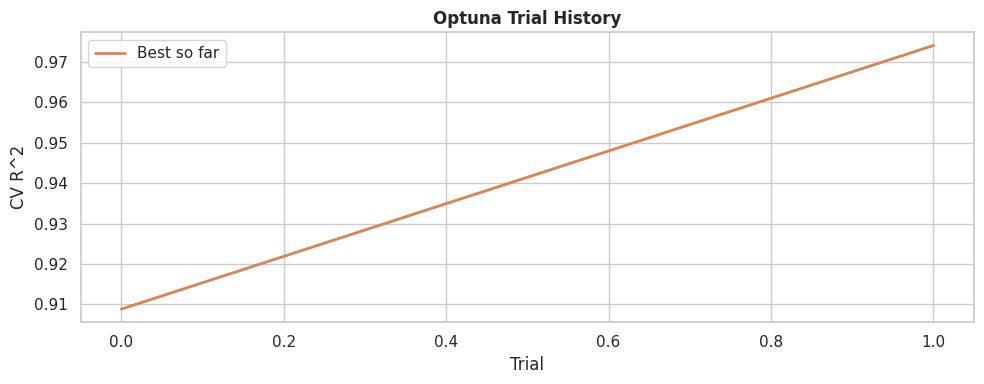

In [ ]:
# Optuna trial history visualizaiton
trial_vals = [t.value for t in study.trials if t.value is not None]

plt.figure(figsize=(10, 4))
plt.plot(trial_vals, alpha=0.5, color="#4C72B0")
plt.plot(pd.Series(trial_vals).cummax(), color="#DD8452", linewidth=2, label="Best so far")
plt.title("Optuna Trial History", fontweight="bold")
plt.xlabel("Trial"); plt.ylabel("CV R^2")
plt.legend(); plt.tight_layout(); plt.show()


## Step 7: Final Model Training on Full Data & Evaluation


In [ ]:
best = study.best_params

final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy=best["impute_strategy"])),
    ("poly", PolynomialFeatures(degree=best["degree"], include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=best["alpha"]))
])
final_pipeline.fit(X, y)

# Separate evaluation pipeline for honest reporting
val_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy=best["impute_strategy"])),
    ("poly", PolynomialFeatures(degree=best["degree"], include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=best["alpha"]))
])
val_pipeline.fit(X_train, y_train)
y_val_pred = val_pipeline.predict(X_val)

test_predictions = final_pipeline.predict(X_test)

r2 = r2_score(y_val, y_val_pred)
mse = mean_squared_error(y_val, y_val_pred)
mae = mean_absolute_error(y_val, y_val_pred)
print(f"Validation R^2: {r2:.4f}")
print(f"Validation RMSE: {np.sqrt(mse):.4f}")
print(f"Validation MAE: {mae:.4f}")


Validation R^2: 0.9753
Validation RMSE: 2.2356
Validation MAE: 1.5811


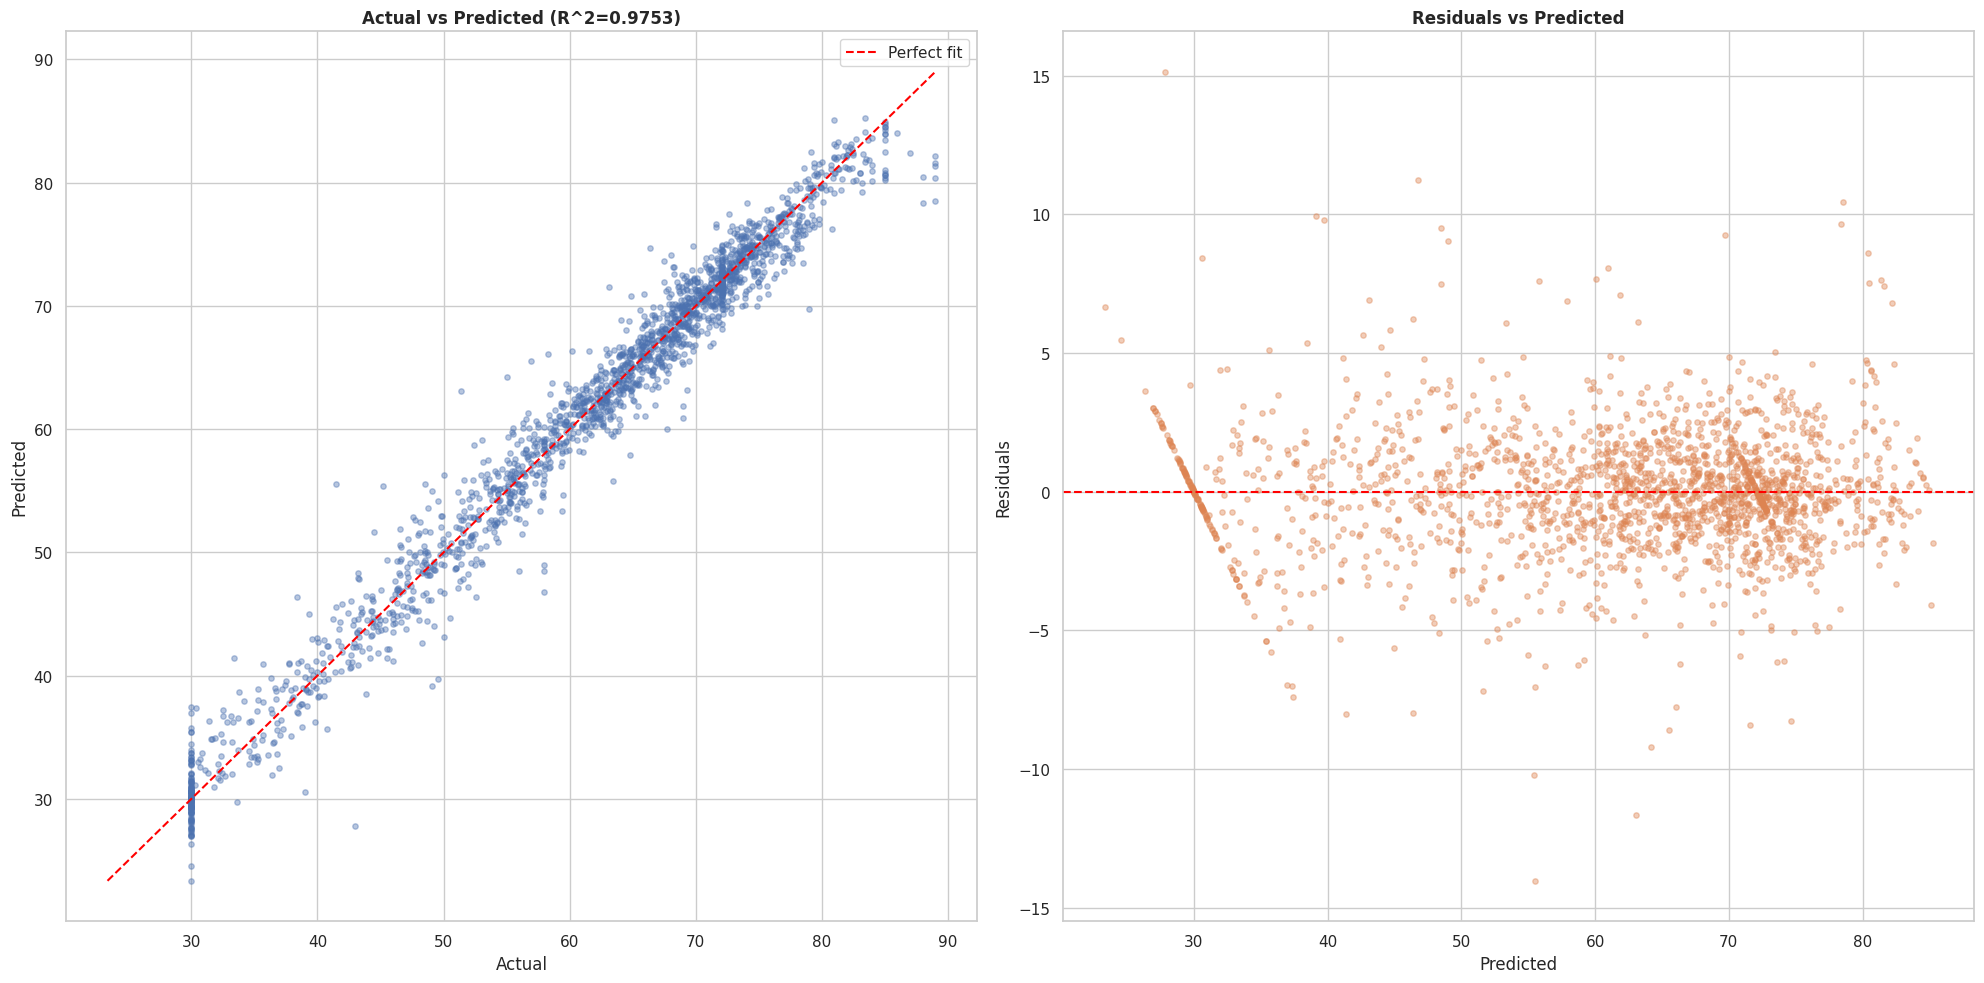

In [ ]:
# Actual vs Predicted + Residuals
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].scatter(y_val, y_val_pred, alpha=0.4, s=15, color="#4C72B0")
mn, mx = min(y_val.min(), y_val_pred.min()), max(y_val.max(), y_val_pred.max())
axes[0].plot([mn, mx], [mn, mx], "r--", linewidth=1.5, label="Perfect fit")
axes[0].set_title(f"Actual vs Predicted (R^2={r2:.4f})", fontweight="bold")
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted"); axes[0].legend()

residuals = y_val - y_val_pred
axes[1].scatter(y_val_pred, residuals, alpha=0.4, s=15, color="#DD8452")
axes[1].axhline(0, color="red", linewidth=1.5, linestyle="--")
axes[1].set_title("Residuals vs Predicted", fontweight="bold")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residuals")

plt.tight_layout(); plt.show()


## Step 8: Create Submission File

In [ ]:
# Create and save submission.csv
submission = pd.DataFrame({
    "id": range(len(test_predictions)),
    "Life Expectancy": test_predictions
})

submission.to_csv("submission.csv", index=False)

print(f"Saved submission.csv")
print(f"Shape: {submission.shape}")
print("\nFirst 10 rows:")
print(submission.head(10))


Saved submission.csv
Shape: (1259, 2)

First 10 rows:
   id  Life Expectancy
0   0        72.472680
1   1        71.035464
2   2        55.406975
3   3        35.432888
4   4        57.291841
5   5        65.988794
6   6        60.138554
7   7        76.204399
8   8        68.284475
9   9        36.387674


# TP2 - Life Expectancy Regression
## CatBoost Model

## I. Setup

### 1.0 Default From Kaggle

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
try:
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            print(os.path.join(dirname, filename))
except:
    pass

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

### 1.1 Import Libraries

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

### 1.2 Load Dataset

In [ ]:
# Load the datasets
try:
    df_eda = pd.read_csv("/kaggle/input/competitions/tp-2-life-expectancy-kasdd-genap-2025-2026/train.csv")
    df_test_full = pd.read_csv("/kaggle/input/competitions/tp-2-life-expectancy-kasdd-genap-2025-2026/test.csv")
except:
    df_eda = pd.read_csv("train.csv")
    df_test_full = pd.read_csv("test.csv")

## II. Data Understanding and Exploratory Data Analysis (EDA)

### 2.1 Data size

In [ ]:
rows, cols = df_eda.shape
print(f'Jumlah data: {rows}')
print(f'Jumlah fitur: {cols}')

Jumlah data: 10070
Jumlah fitur: 21


### 2.2 Data type and Non-Null Data

In [ ]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             10070 non-null  int64  
 1   Status                           10070 non-null  object 
 2   Life expectancy                  10062 non-null  float64
 3   Adult Mortality                  10062 non-null  float64
 4   infant deaths                    10070 non-null  int64  
 5   Alcohol                          9920 non-null   float64
 6   percentage expenditure           10070 non-null  float64
 7   Measles                          10070 non-null  int64  
 8   BMI                              10047 non-null  float64
 9   under-five deaths                10070 non-null  int64  
 10  Total expenditure                9894 non-null   float64
 11  GDP                              9707 non-null   float64
 12  thinness  1-19 yea

In [ ]:
df_test_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             1259 non-null   int64  
 1   Adult Mortality                  1259 non-null   float64
 2   infant deaths                    1259 non-null   int64  
 3   Alcohol                          1242 non-null   float64
 4   percentage expenditure           1259 non-null   float64
 5   Measles                          1259 non-null   int64  
 6   BMI                              1253 non-null   float64
 7   under-five deaths                1259 non-null   int64  
 8   Total expenditure                1239 non-null   float64
 9   GDP                              1217 non-null   float64
 10  thinness  1-19 years             1253 non-null   float64
 11  thinness 5-9 years               1253 non-null   float64
 12  Income composition o

### 2.3 Descriptive Statistics (Numerical and Categorical)

In [ ]:
# Ringkasan statistik fitur numerik
display(df_eda.describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


In [ ]:
# Ringkasan statistik fitur kategorikal
cat_desc = df_eda.describe(include=['object']).T
if not cat_desc.empty:
    display(cat_desc)
else:
    print('Tidak ada fitur kategorikal.')

,count,unique,top,freq
Status,10070,2,Developing,8380


Cuma ada satu variabel non-numerik dan variabel tersebut adalah variabel target

In [ ]:
# Statistik untuk fitur lainnya
focus_cols = ['Life expectancy', 'Total expenditure', 'percentage expenditure', 'GDP', 'Income composition of resources', 'Schooling']
focus_cols = [c for c in focus_cols if c in df_eda.columns]

summary_rows = []
for col in focus_cols:
    s = df_eda[col].dropna()
    iqr = s.quantile(0.75) - s.quantile(0.25)
    cv = s.std() / s.mean() if s.mean() != 0 else np.nan
    summary_rows.append({
        'feature': col,
        'mean': s.mean(),
        'median': s.median(),
        'mode': s.mode().iloc[0] if not s.mode().empty else np.nan,
        'std': s.std(),
        'min': s.min(),
        'q1': s.quantile(0.25),
        'q3': s.quantile(0.75),
        'iqr': iqr,
        'max': s.max(),
        'range': s.max() - s.min(),
        'skewness': s.skew(),
        'kurtosis': s.kurt(),
        'coef_var': cv
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,feature,mean,median,mode,std,min,q1,q3,iqr,max,range,skewness,kurtosis,coef_var
0,Life expectancy,61.686064,65.740650,30.0,14.203480,30.00000,53.705956,72.100000,18.394044,89.000000,59.000000,-0.814825,-0.231248,0.230254
1,Total expenditure,5.321350,4.850228,0.0,4.252678,0.00000,2.385204,7.100000,4.714796,20.000000,20.000000,1.226778,1.947479,0.799173
2,percentage expenditure,196.102675,0.000000,0.0,1003.054608,0.00000,0.000000,100.000000,100.000000,19099.045060,19099.045060,9.758529,117.844912,5.114946
3,GDP,4303.474007,168.648254,10.0,12154.796976,1.68135,10.000000,1766.947595,1756.947595,125097.788731,125096.107381,4.718354,26.716303,2.824415
4,Income composition of resources,0.479002,0.539363,0.0,0.267276,0.00000,0.293527,0.679000,0.385473,0.948000,0.948000,-0.515077,-0.890881,0.557985
5,Schooling,9.044535,10.106075,0.0,5.145238,0.00000,5.355685,12.569284,7.213599,25.000000,25.000000,-0.273275,-0.528412,0.568878


Kolom `Total expenditure`, `percentage expenditure`, dan `thinness 1-19 years` tidak benar-benar merepresentasikan deskripsi asli kolomnya:
- `percentage expenditure`: Pengeluaran kesehatan sebagai persentase dari GDP per kapita (%).
- `Total expenditure`: Pengeluaran kesehatan pemerintah sebagai persentase dari total pengeluaran pemerintah (%).
- `thinness 1-19 years`: Prevalensi kekurusan pada remaja usia 10-19 tahun (%).



Deskripsi semua kolom:
- `Year`: Tahun pengamatan data (1950-2015).
- `Population`: Jumlah populasi negara.
- `Life expectancy`: Harapan hidup dalam satuan tahun.
- `Adult Mortality`: Tingkat kematian dewasa (rentang usia 15-60 tahun) per 1000 populasi.
- `infant deaths`: Jumlah kematian bayi per 1000 populasi.
- `under-five deaths`: Jumlah kematian anak di bawah 5 tahun per 1000 populasi.
- `HIV/AIDS`: Kematian akibat HIV/AIDS per 1000 kelahiran hidup (usia 0-4 tahun).
- `Measles`: Jumlah kasus penyakit campak yang dilaporkan per 1000 populasi.
- `Hepatitis B`: Persentase cakupan imunisasi Hepatitis B pada anak usia 1 tahun (%).
- `Polio`: Persentase cakupan imunisasi Polio pada anak usia 1 tahun (%).
- `Diphtheria`: Persentase cakupan imunisasi DTP3 (Difteri-Tetanus-Pertusis) pada anak usia 1 tahun (%).
- `Alcohol`: Konsumsi alkohol per kapita (liter alkohol murni per orang dengan usia 15+ tahun).
- `BMI`: Body Mass Index rata-rata populasi.
- `thinness 1-19 years`: Prevalensi kekurusan pada remaja usia 10-19 tahun (%).
- `thinness 5-9 years`: Prevalensi kekurusan pada anak usia 5-9 tahun (%).
- `GDP`: Gross Domestic Product per kapita dalam USD.
- `percentage expenditure`: Pengeluaran kesehatan sebagai persentase dari GDP per kapita (%).
- `Total expenditure`: Pengeluaran kesehatan pemerintah sebagai persentase dari total pengeluaran pemerintah (%).
- `Schooling`: Rata-rata lama sekolah atau pendidikan dalam satuan tahun.
- `Income composition of resources`: Indeks Human Development Index dalam hal komposisi pendapatan sumber daya (menggunakan skala 0-1).


### 2.4 Missing Values Analysis

In [ ]:
# Cari kolom dengan missing values dan persentasenya
missing_values = df_eda.isna().sum().reset_index()
missing_values.columns = ['feature', 'missing_count']
missing_values['percentage'] = (missing_values['missing_count'] / len(df_eda)) * 100
print("Kolom dengan Missing Values:")
print(missing_values)

Kolom dengan Missing Values:
                            feature  missing_count  percentage
0                              Year              0    0.000000
1                            Status              0    0.000000
2                   Life expectancy              8    0.079444
3                   Adult Mortality              8    0.079444
4                     infant deaths              0    0.000000
5                           Alcohol            150    1.489573
6            percentage expenditure              0    0.000000
7                           Measles              0    0.000000
8                               BMI             23    0.228401
9                 under-five deaths              0    0.000000
10                Total expenditure            176    1.747766
11                              GDP            363    3.604767
12             thinness  1-19 years             23    0.228401
13               thinness 5-9 years             23    0.228401
14  Income composition of 

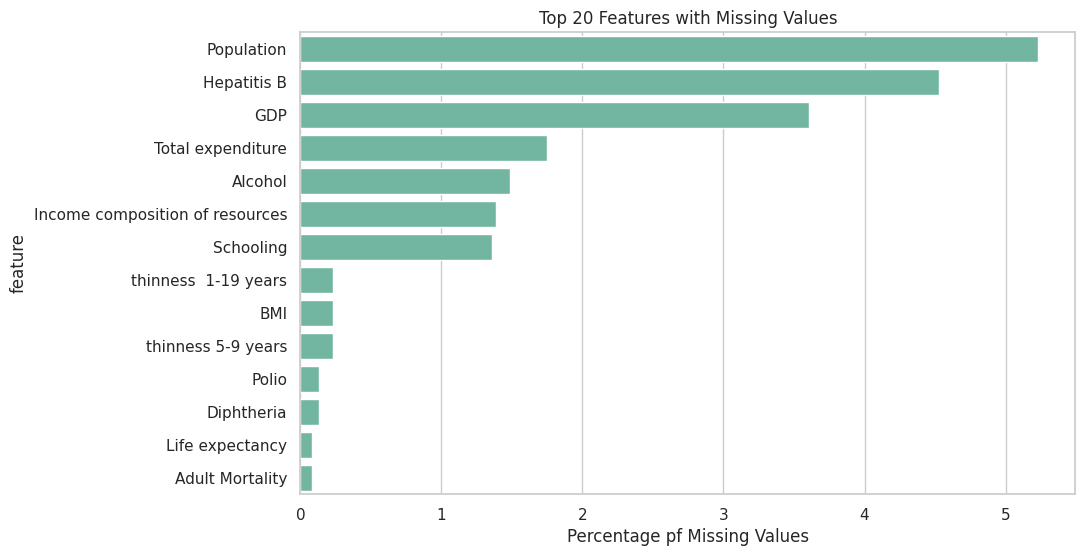

In [ ]:
missing_values = missing_values[missing_values['missing_count'] > 0].sort_values(by='percentage', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='percentage', y='feature', data=missing_values.head(20))
plt.title('Top 20 Features with Missing Values')
plt.xlabel('Percentage pf Missing Values')
plt.show()

persentase missing values di setiap kolomnya selalu <20, berarti semuanya bisa diimpute

### 2.5 Life Expectancy Trend for Developed and Developing Countries

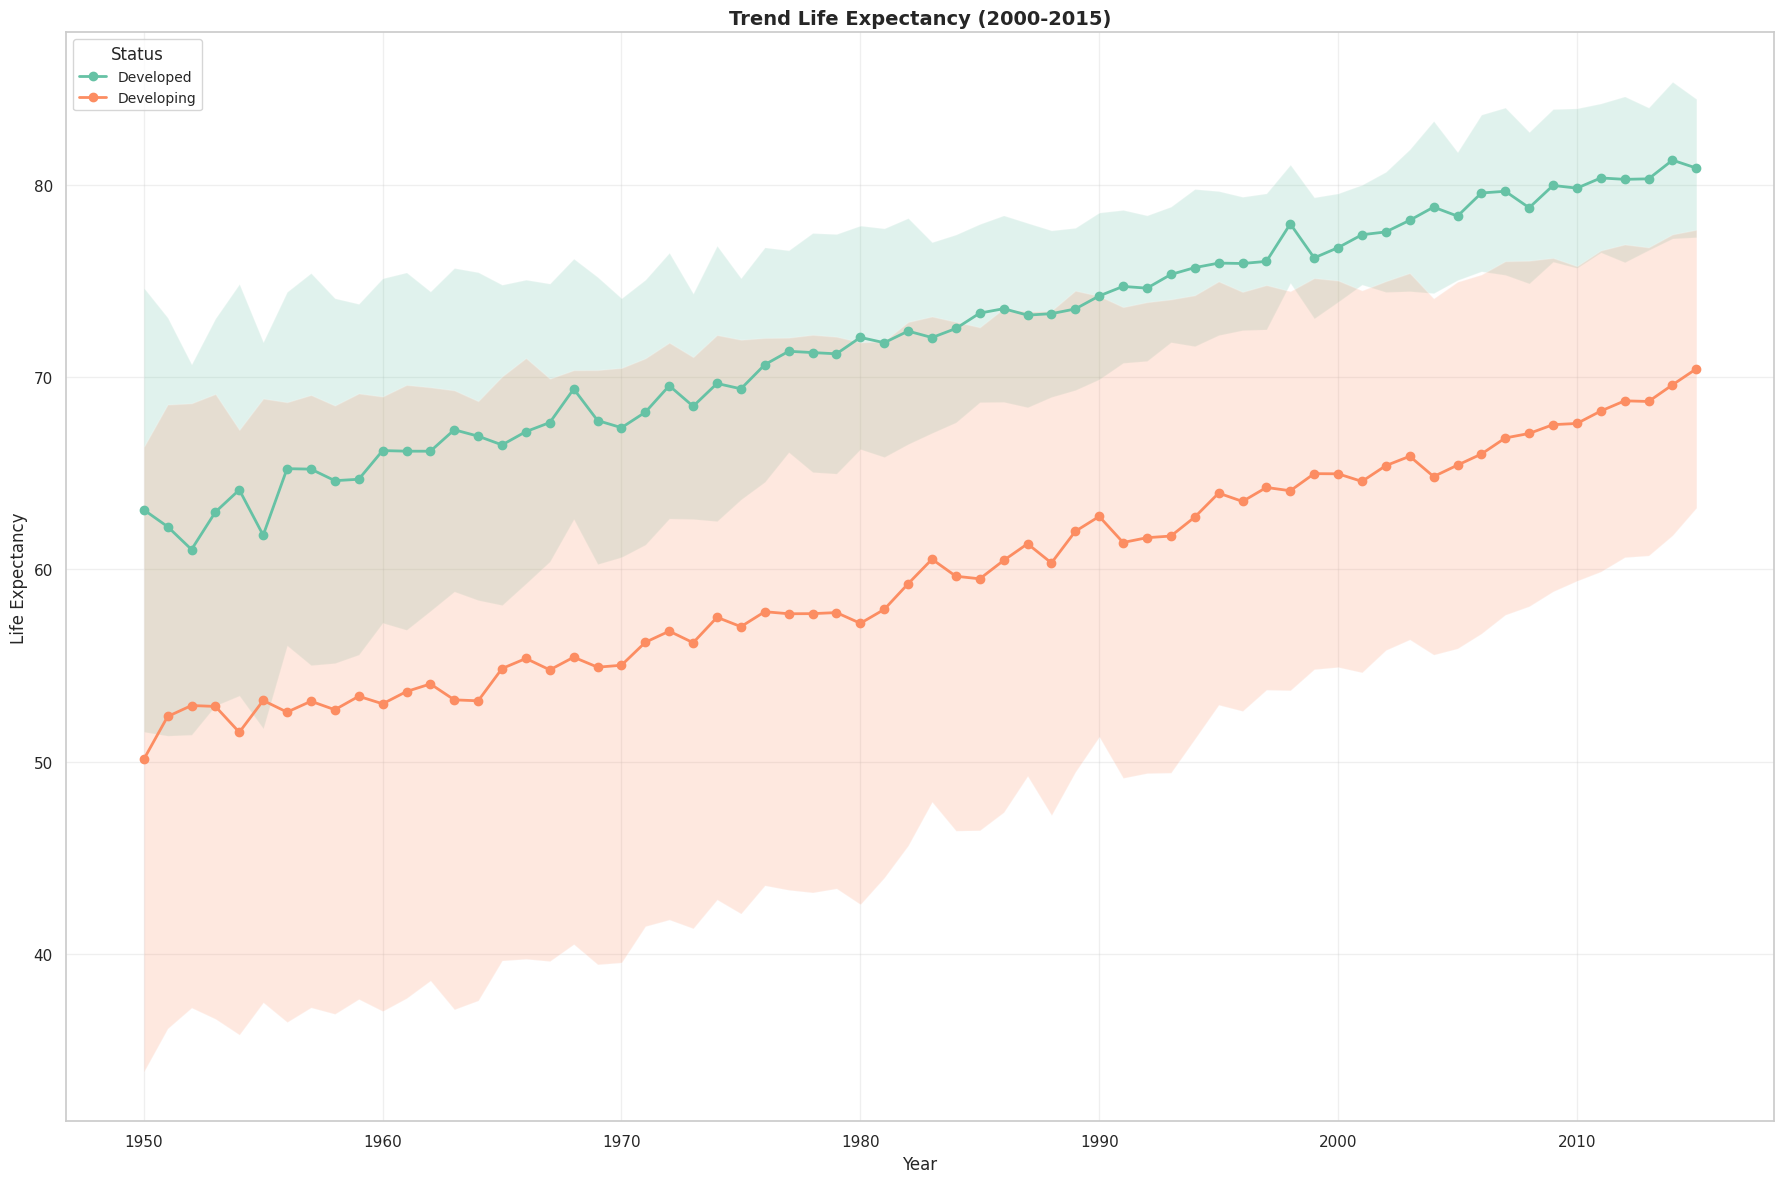

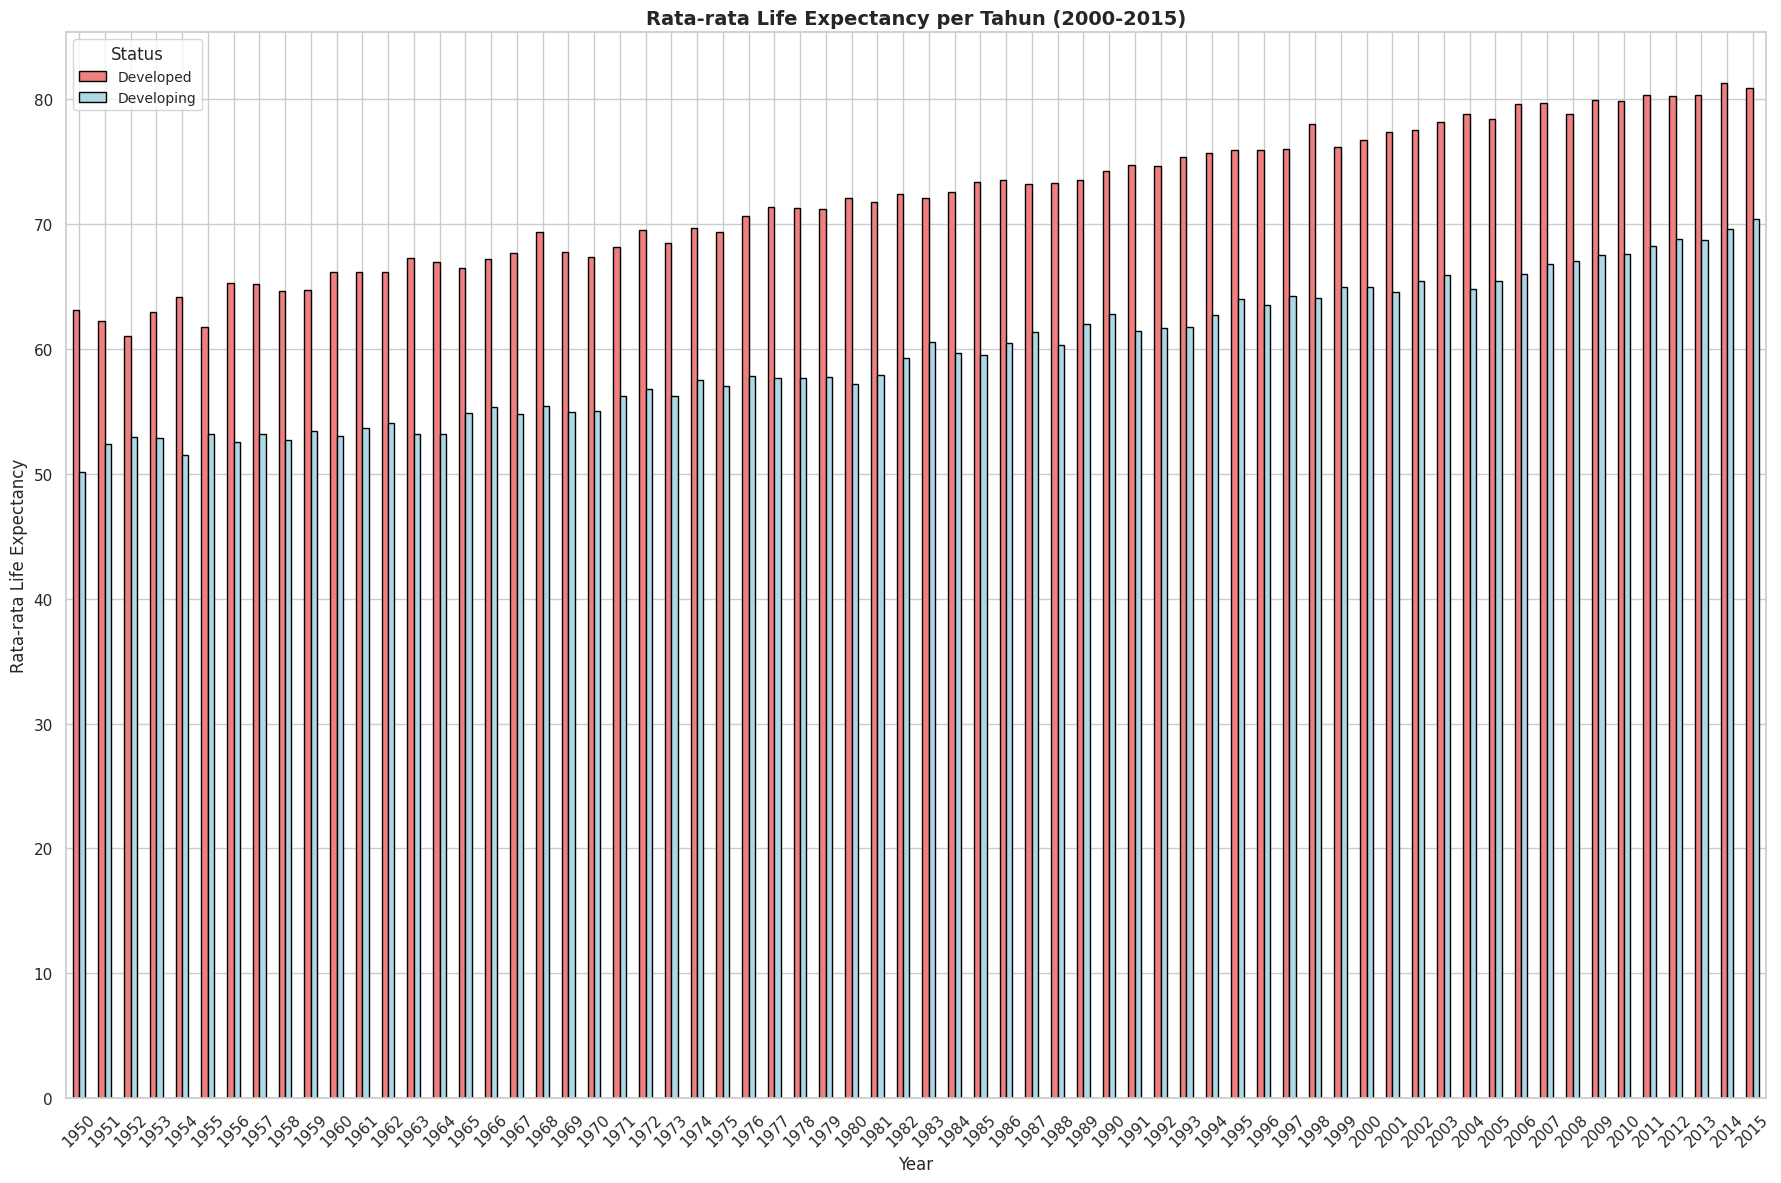

In [ ]:
# Filter data untuk tahun 2000-2015
df_LE_trend = df_eda.copy()

# 4.1 Line plot: Trend Life Expectancy per tahun
yearly_stats = df_eda.groupby(['Year', 'Status'])['Life expectancy'].agg(['mean', 'std']).reset_index()

fig1, ax1 = plt.subplots(figsize=(18, 12))
for status in ['Developed', 'Developing']:
    subset = yearly_stats[yearly_stats['Status'] == status]
    ax1.plot(subset['Year'], subset['mean'], marker='o', linewidth=2, label=status)
    ax1.fill_between(subset['Year'],
                     subset['mean'] - subset['std'],
                     subset['mean'] + subset['std'],
                     alpha=0.2)

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Life Expectancy', fontsize=12)
ax1.set_title('Trend Life Expectancy (2000-2015)', fontsize=14, fontweight='bold')
ax1.legend(title='Status', fontsize=10)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4.2 Bar plot: Rata-rata Life Expectancy per tahun
pivot_data = yearly_stats.pivot(index='Year', columns='Status', values='mean')

fig2, ax2 = plt.subplots(figsize=(18, 12))
pivot_data.plot(kind='bar', ax=ax2, color=['lightcoral', 'lightblue'], edgecolor='black')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Rata-rata Life Expectancy', fontsize=12)
ax2.set_title('Rata-rata Life Expectancy per Tahun (2000-2015)', fontsize=14, fontweight='bold')
ax2.legend(title='Status', fontsize=10)
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Analisis statistik
print("\nAnalisis Statistik:")
print("-" * 50)

# Rata-rata Life Expectancy per tahun dan status
print("Rata-rata Life Expectancy per Tahun dan Status:")
yearly_mean = df_LE_trend.groupby(['Year', 'Status'])['Life expectancy'].mean().unstack()
print(yearly_mean)

# Rata-rata keseluruhan
print(f"\nRata-rata Life Expectancy:")
overall_mean = df_LE_trend.groupby('Status')['Life expectancy'].agg(['mean', 'std', 'min', 'max'])
print(overall_mean)

# Trend analysis menggunakan regresi linear
print(f"\nTrend Analysis (Regresi Linear):")
for status in ['Developed', 'Developing']:
    subset = df_LE_trend[df_LE_trend['Status'] == status]
    yearly_avg = subset.groupby('Year')['Life expectancy'].mean()

    slope, intercept, r_value, p_value, std_err = stats.linregress(yearly_avg.index, yearly_avg.values)
    print(f"\n{status}:")
    print(f"  Slope: {slope:.4f} (perubahan per tahun)")
    print(f"  R-squared: {r_value**2:.4f}")
    print(f"  P-value: {p_value:.6f}")
    print(f"  Signifikan (alpha=0.05): {'Ya' if p_value < 0.05 else 'Tidak'}")


Analisis Statistik:
--------------------------------------------------
Rata-rata Life Expectancy per Tahun dan Status:
Status  Developed  Developing
Year                         
1950    63.101037   50.119853
1951    62.222672   52.351812
1952    61.034345   52.922755
1953    62.986369   52.874513
1954    64.138626   51.531219
...           ...         ...
2011    80.356522   68.236719
2012    80.284000   68.766393
2013    80.310714   68.733613
2014    81.282609   69.597479
2015    80.869231   70.433333

[66 rows x 2 columns]

Rata-rata Life Expectancy:
                 mean        std        min   max
Status                                           
Developed   72.108147   8.394009  35.802159  89.0
Developing  59.582228  14.208987  30.000000  89.0

Trend Analysis (Regresi Linear):

Developed:
  Slope: 0.2929 (perubahan per tahun)
  R-squared: 0.9868
  P-value: 0.000000
  Signifikan (alpha=0.05): Ya

Developing:
  Slope: 0.2838 (perubahan per tahun)
  R-squared: 0.9813
  P-value: 0.0

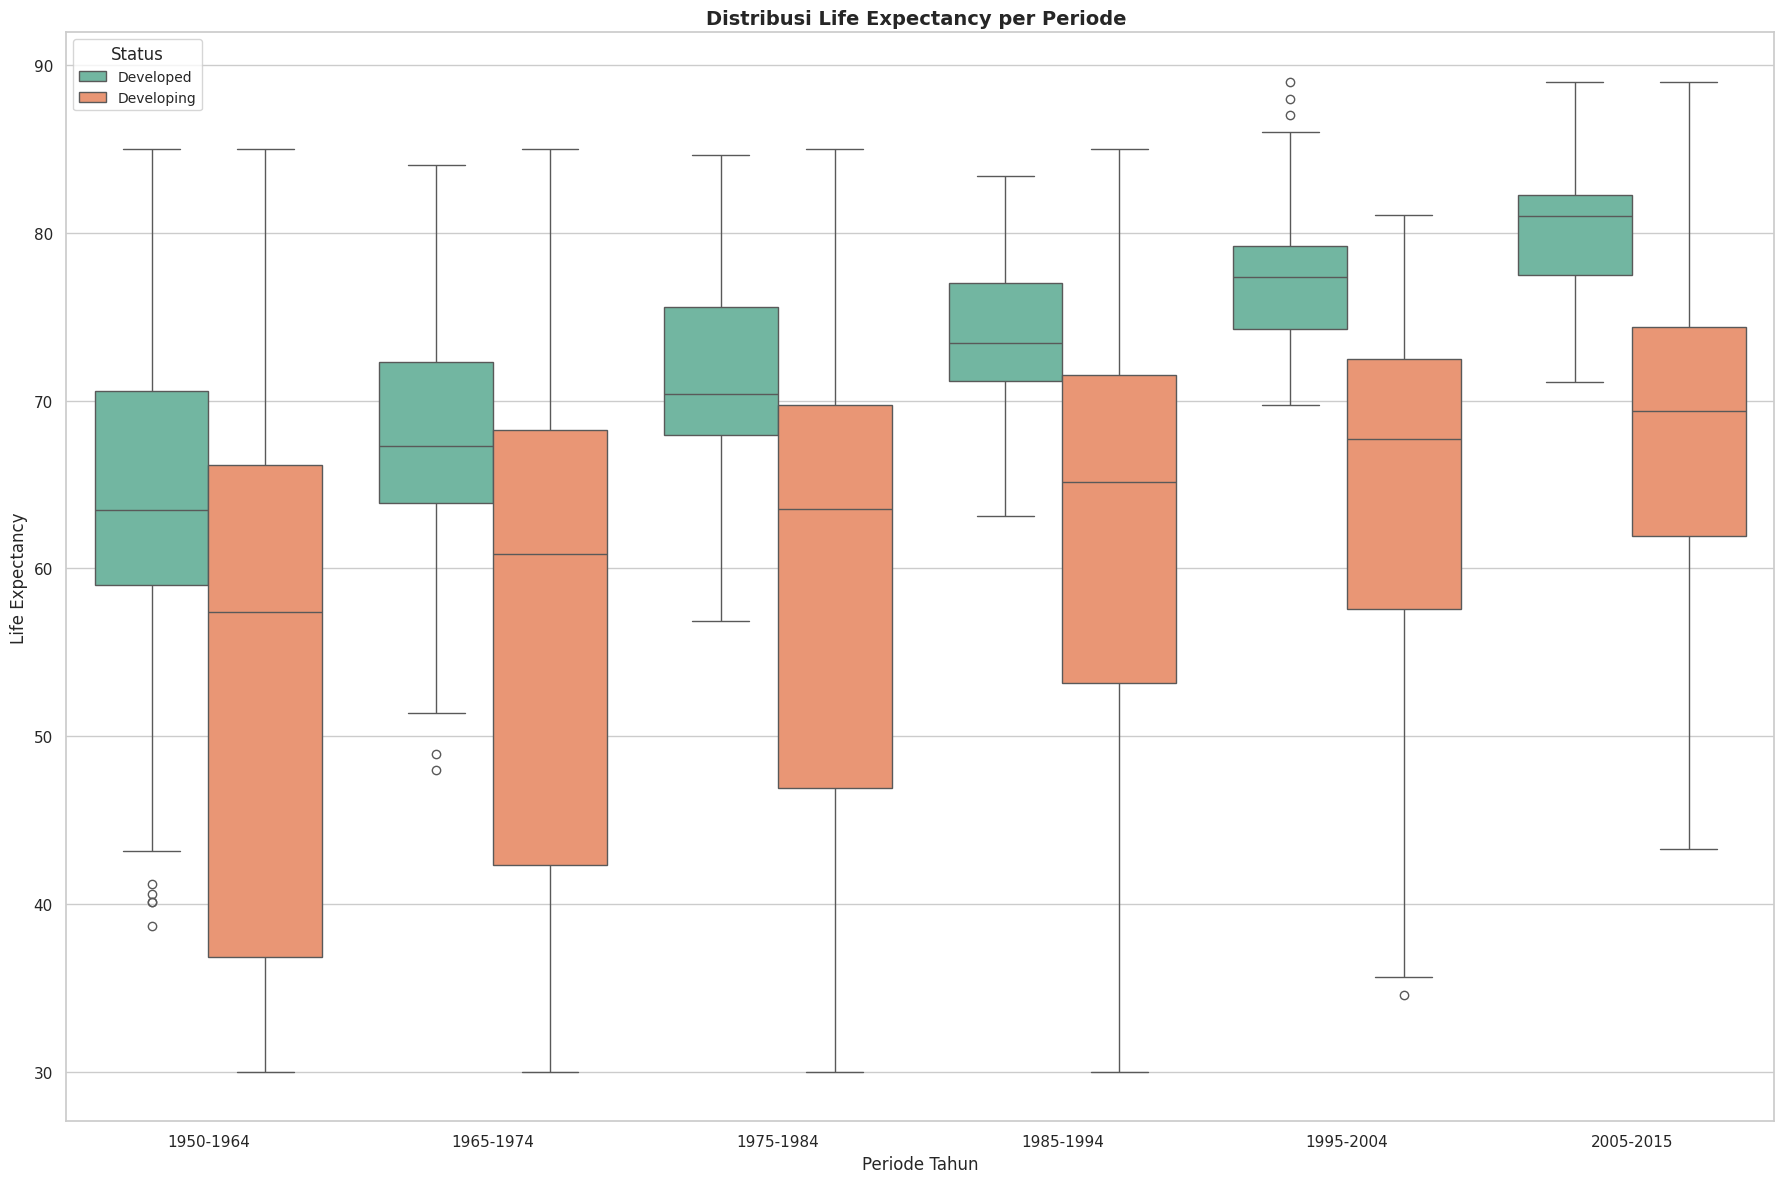

In [ ]:
# 4.3 Box plot: Distribusi Life Expectancy per 5 tahun
df_LE_trend['Year_Group'] = pd.cut(df_LE_trend['Year'],
                                      bins=[1950, 1964, 1974, 1984, 1994, 2004, 2015],
                                      labels=['1950-1964', '1965-1974', '1975-1984', '1985-1994', '1995-2004', '2005-2015'])

fig3, ax3 = plt.subplots(figsize=(18, 12))
sns.boxplot(data=df_LE_trend, x='Year_Group', y='Life expectancy', hue='Status',
            ax=ax3, palette='Set2')
ax3.set_xlabel('Periode Tahun', fontsize=12)
ax3.set_ylabel('Life Expectancy', fontsize=12)
ax3.set_title('Distribusi Life Expectancy per Periode ', fontsize=14, fontweight='bold')
ax3.legend(title='Status', fontsize=10)
plt.tight_layout()
plt.show()

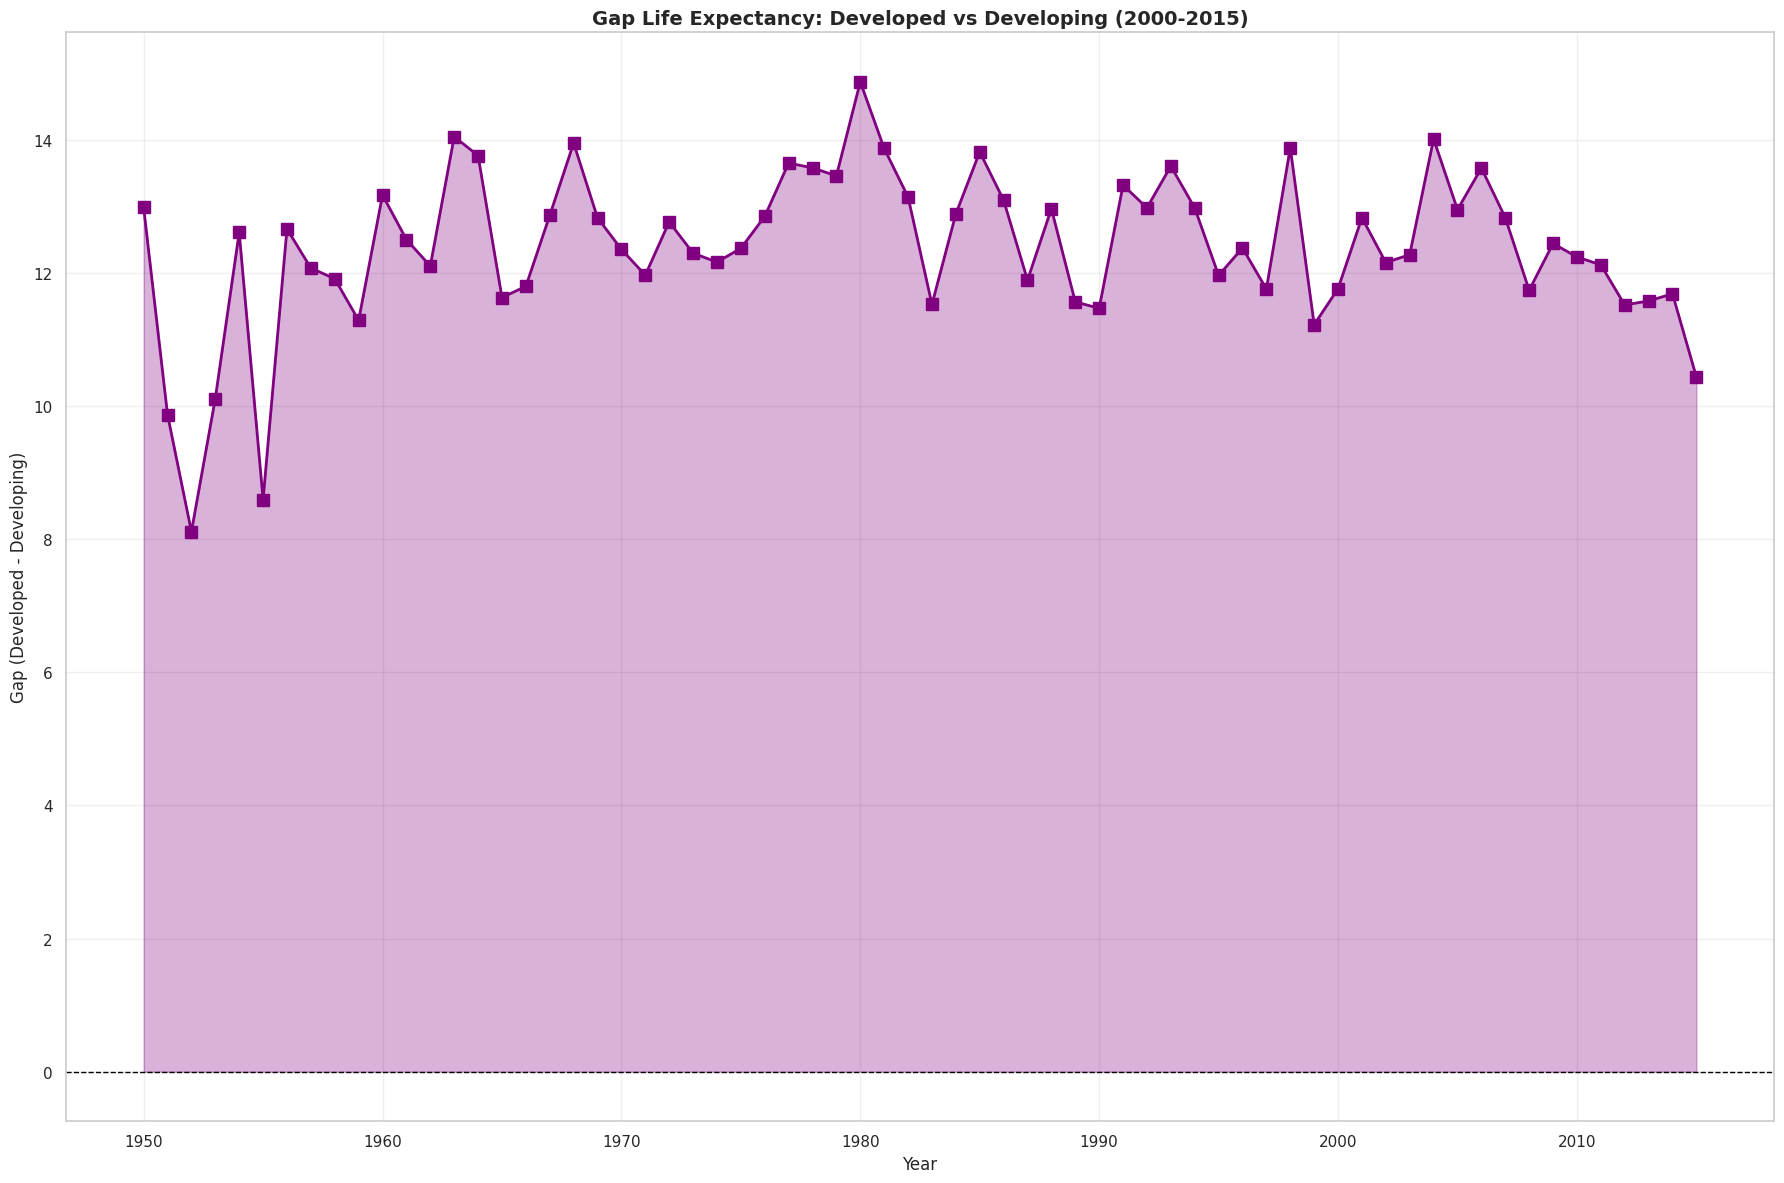


Gap Life Expectancy (Developed - Developing):
Year
1950    12.981183
1951     9.870860
1952     8.111590
1953    10.111856
1954    12.607408
          ...    
2011    12.119803
2012    11.517607
2013    11.577101
2014    11.685130
2015    10.435897
Length: 66, dtype: float64

Rata-rata Gap: 12.39
Gap Minimum: 8.11 (Tahun 1952)
Gap Maksimum: 14.87 (Tahun 1980)


In [ ]:
# 4.4 Line plot: Gap antara Developed dan Developing
gap_data = yearly_stats.pivot(index='Year', columns='Status', values='mean')
gap_data['Gap'] = gap_data['Developed'] - gap_data['Developing']

fig4, ax4 = plt.subplots(figsize=(18, 12))
ax4.plot(gap_data.index, gap_data['Gap'], marker='s', linewidth=2, color='purple', markersize=8)
ax4.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax4.fill_between(gap_data.index, 0, gap_data['Gap'], alpha=0.3, color='purple')
ax4.set_xlabel('Year', fontsize=12)
ax4.set_ylabel('Gap (Developed - Developing)', fontsize=12)
ax4.set_title('Gap Life Expectancy: Developed vs Developing (2000-2015)', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gap analysis
gap_data = yearly_mean['Developed'] - yearly_mean['Developing']
print(f"\nGap Life Expectancy (Developed - Developing):")
print(gap_data)
print(f"\nRata-rata Gap: {gap_data.mean():.2f}")
print(f"Gap Minimum: {gap_data.min():.2f} (Tahun {gap_data.idxmin()})")
print(f"Gap Maksimum: {gap_data.max():.2f} (Tahun {gap_data.idxmax()})")

**RINGKASAN ANALISIS**

Trend Life Expectancy:
- Life Expectancy meningkat untuk kedua kategori negara
- Gap antara Developed dan Developing volatil
- Tidak ada status negara yang menunjukkan peningkatan yang lebih cepat

### 2.6 Correlation Between Death-Correlated (but Without Sickness Description) Variables and Life Expectancy

Kolom yang dianalisis: ['Adult Mortality', 'infant deaths', 'under-five deaths', 'Total Under-Five Deaths', 'Adult to Child Mortality Ratio']


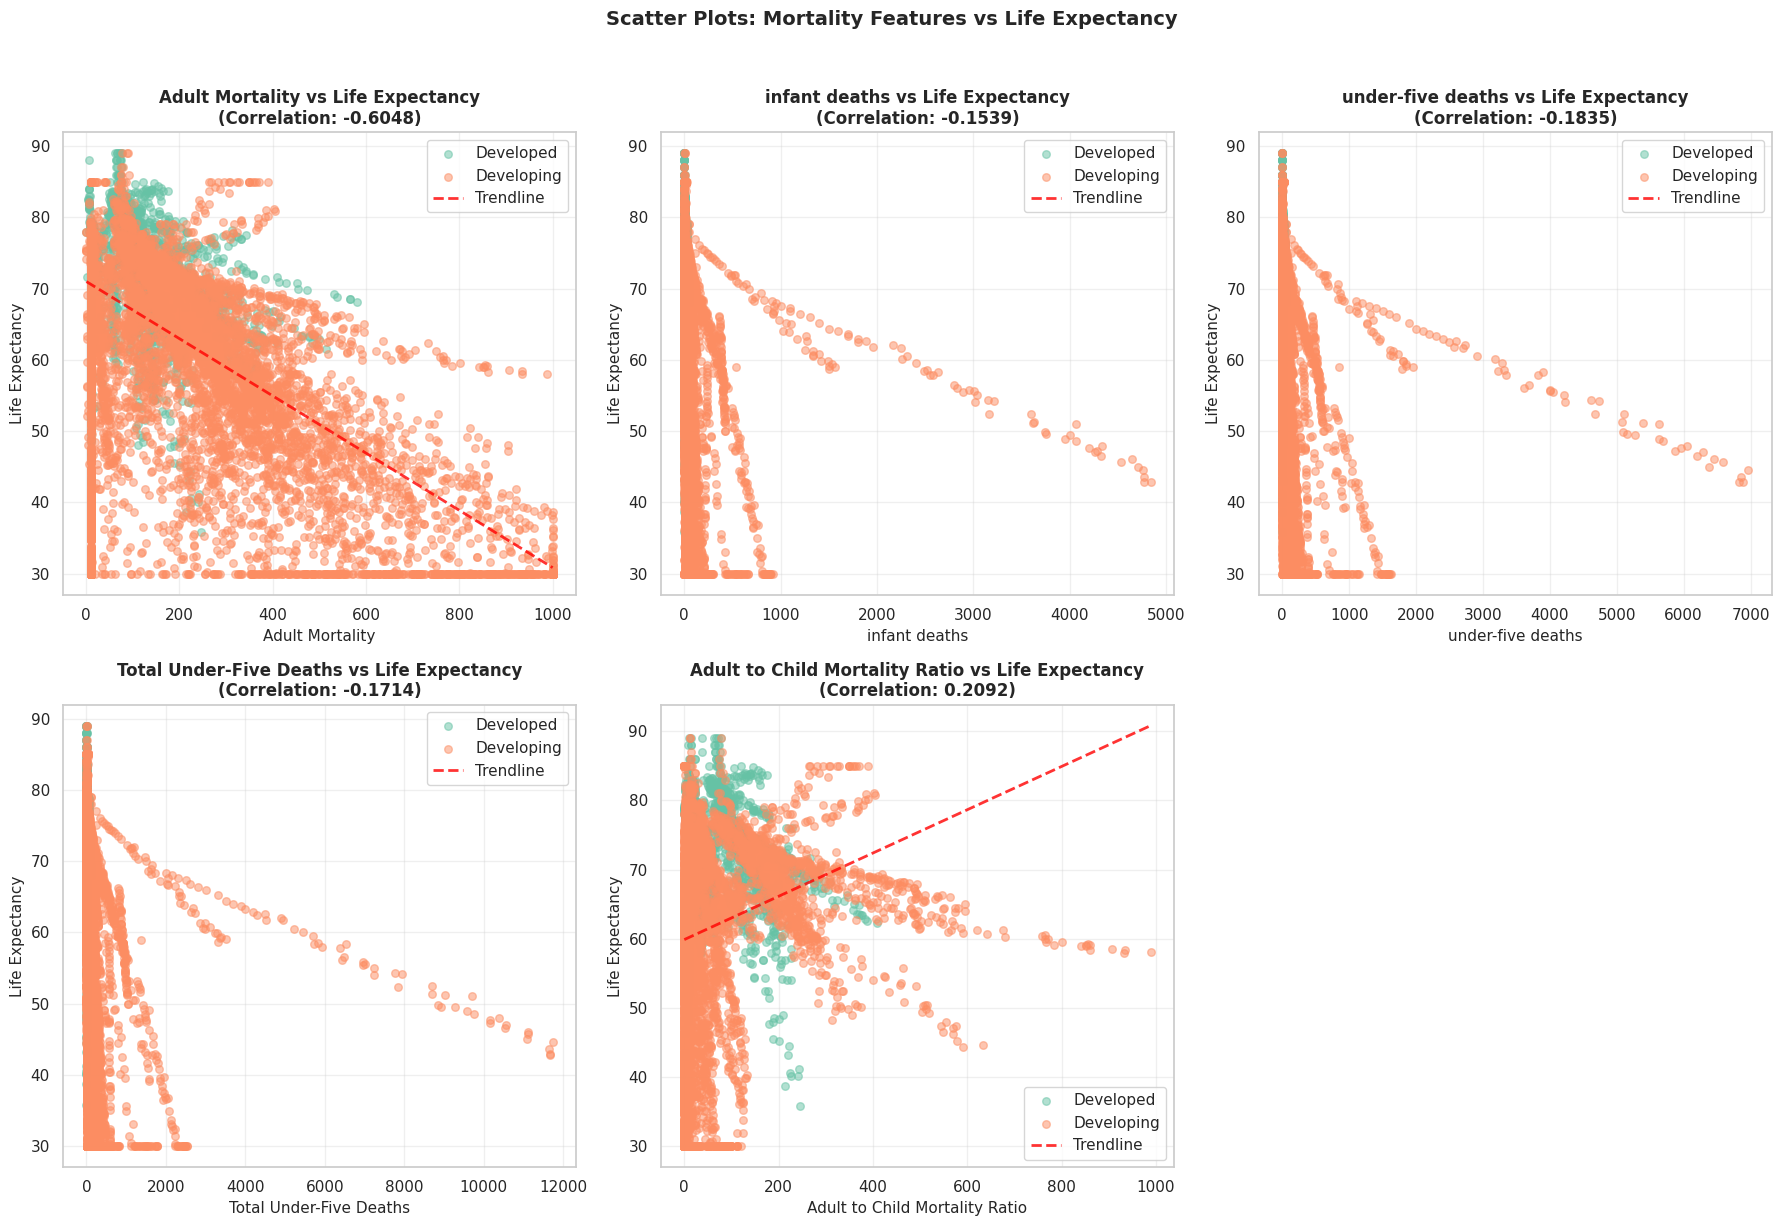

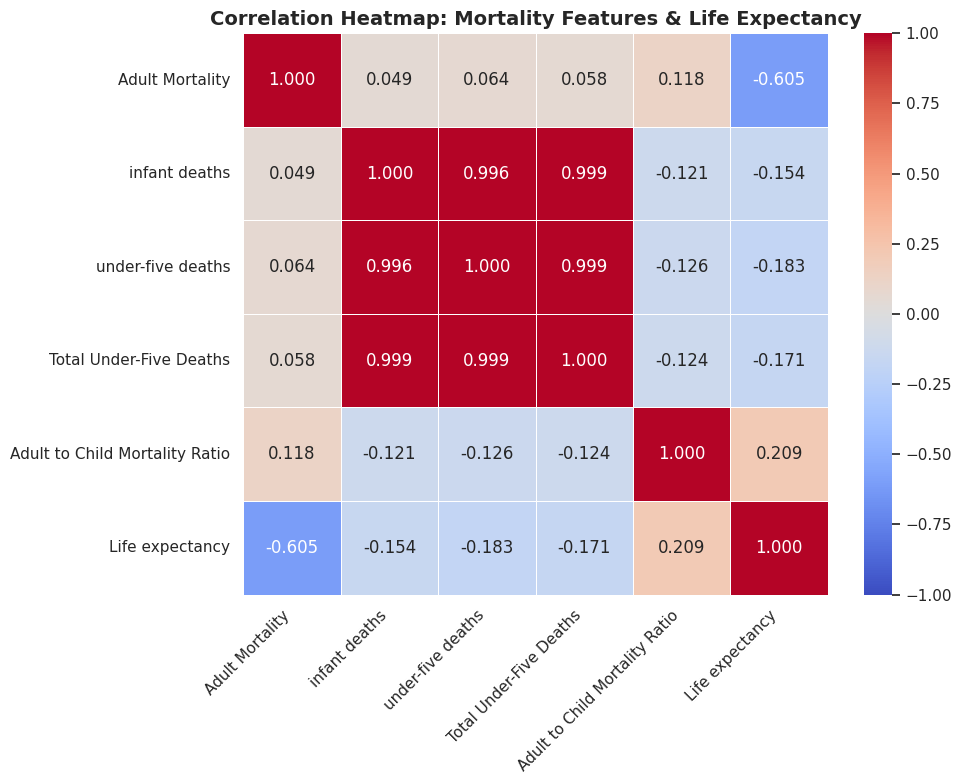

KORELASI ANTARA KOLOM MORTALITY DENGAN LIFE EXPECTANCY


,Feature,Correlation,Abs_Correlation,Relationship
0,Adult Mortality,-0.604769,0.604769,Negatif
4,Adult to Child Mortality Ratio,0.209222,0.209222,Positif
2,under-five deaths,-0.183468,0.183468,Negatif
3,Total Under-Five Deaths,-0.171356,0.171356,Negatif
1,infant deaths,-0.153874,0.153874,Negatif


In [ ]:
# EDA: Hubungan dan Korelasi antara Kolom-Kolom Mortality dengan Life Expectancy
# Correlation Between Death-Correlated (but Without Sickness Description) Variables and Life Expectancy
# Kolom yang dianalisis: Adult Mortality, infant deaths, under-five deaths, Total Under-Five Deaths, Adult to Child Mortality Ratio

df_new = df_eda.copy()

df_new['Total Under-Five Deaths'] = df_new['infant deaths'] + df_new['under-five deaths']
df_new['Adult to Child Mortality Ratio'] = df_new['Adult Mortality'] / (df_new['Total Under-Five Deaths'] + 1)  # Tambahkan 1 untuk menghindari pembagian dengan nol

# Pastikan kolom baru sudah ada di df_new
if 'Total Under-Five Deaths' not in df_new.columns:
    df_new['Total Under-Five Deaths'] = df_new['infant deaths'] + df_new['under-five deaths']
    df_new['Adult to Child Mortality Ratio'] = df_new['Adult Mortality'] / (df_new['Total Under-Five Deaths'] + 1)

# Definisi kolom mortality yang akan dianalisis
mortality_cols = [
    'Adult Mortality',
    'infant deaths',
    'under-five deaths',
    'Total Under-Five Deaths',
    'Adult to Child Mortality Ratio'
]

# Filter hanya kolom yang tersedia di dataframe
available_cols = [col for col in mortality_cols if col in df_new.columns]
print(f"Kolom yang dianalisis: {available_cols}")

# ==============================================================================
# 1. SCATTER PLOTS: Hubungan setiap kolom mortality dengan Life Expectancy
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(available_cols):
    ax = axes[idx]

    # Scatter plot dengan warna berdasarkan Status (jika ada)
    if 'Status' in df_new.columns:
        for status in df_new['Status'].unique():
            mask = df_new['Status'] == status
            ax.scatter(df_new.loc[mask, col], df_new.loc[mask, 'Life expectancy'],
                      alpha=0.5, label=status, s=30)
        ax.legend()
    else:
        ax.scatter(df_new[col], df_new['Life expectancy'], alpha=0.5, s=30)

    # Hitung dan tampilkan korelasi
    corr = df_new[col].corr(df_new['Life expectancy'])
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel('Life Expectancy', fontsize=11)
    ax.set_title(f'{col} vs Life Expectancy\n(Correlation: {corr:.4f})', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # Tambahkan trendline
    z = np.polyfit(df_new[col].dropna(), df_new.loc[df_new[col].notna(), 'Life expectancy'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df_new[col].min(), df_new[col].max(), 100)
    ax.plot(x_line, p(x_line), "r--", alpha=0.8, linewidth=2, label='Trendline')
    ax.legend()

# Hapus axes kosong jika ada
for idx in range(len(available_cols), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle('Scatter Plots: Mortality Features vs Life Expectancy', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 2. CORRELATION HEATMAP: Korelasi antar kolom mortality dan dengan Life Expectancy
# ==============================================================================
# Pilih kolom yang relevan untuk heatmap
heatmap_cols = available_cols + ['Life expectancy']
corr_matrix = df_new[heatmap_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # Upper triangle mask
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5,
            annot_kws={'size': 12})
plt.title('Correlation Heatmap: Mortality Features & Life Expectancy', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. DETAILED CORRELATION ANALYSIS
# ==============================================================================
print("=" * 70)
print("KORELASI ANTARA KOLOM MORTALITY DENGAN LIFE EXPECTANCY")
print("=" * 70)

correlation_results = []
for col in available_cols:
    corr = df_new[col].corr(df_new['Life expectancy'])
    correlation_results.append({
        'Feature': col,
        'Correlation': corr,
        'Abs_Correlation': abs(corr),
        'Relationship': 'Negatif' if corr < 0 else 'Positif'
    })

corr_df = pd.DataFrame(correlation_results).sort_values('Abs_Correlation', ascending=False)
display(corr_df)

In [ ]:
# Interpretasi
print("\n" + "=" * 70)
print("INTERPRETASI")
print("=" * 70)
for _, row in corr_df.iterrows():
    strength = "kuat" if row['Abs_Correlation'] > 0.5 else "sedang" if row['Abs_Correlation'] > 0.3 else "lemah"
    print(f"- {row['Feature']}: Korelasi {row['Relationship'].lower()} {strength} ({row['Correlation']:.4f})")


INTERPRETASI
- Adult Mortality: Korelasi negatif kuat (-0.6048)
- Adult to Child Mortality Ratio: Korelasi positif lemah (0.2092)
- under-five deaths: Korelasi negatif lemah (-0.1835)
- Total Under-Five Deaths: Korelasi negatif lemah (-0.1714)
- infant deaths: Korelasi negatif lemah (-0.1539)


### 2.7 Heatmap of Features Correlation

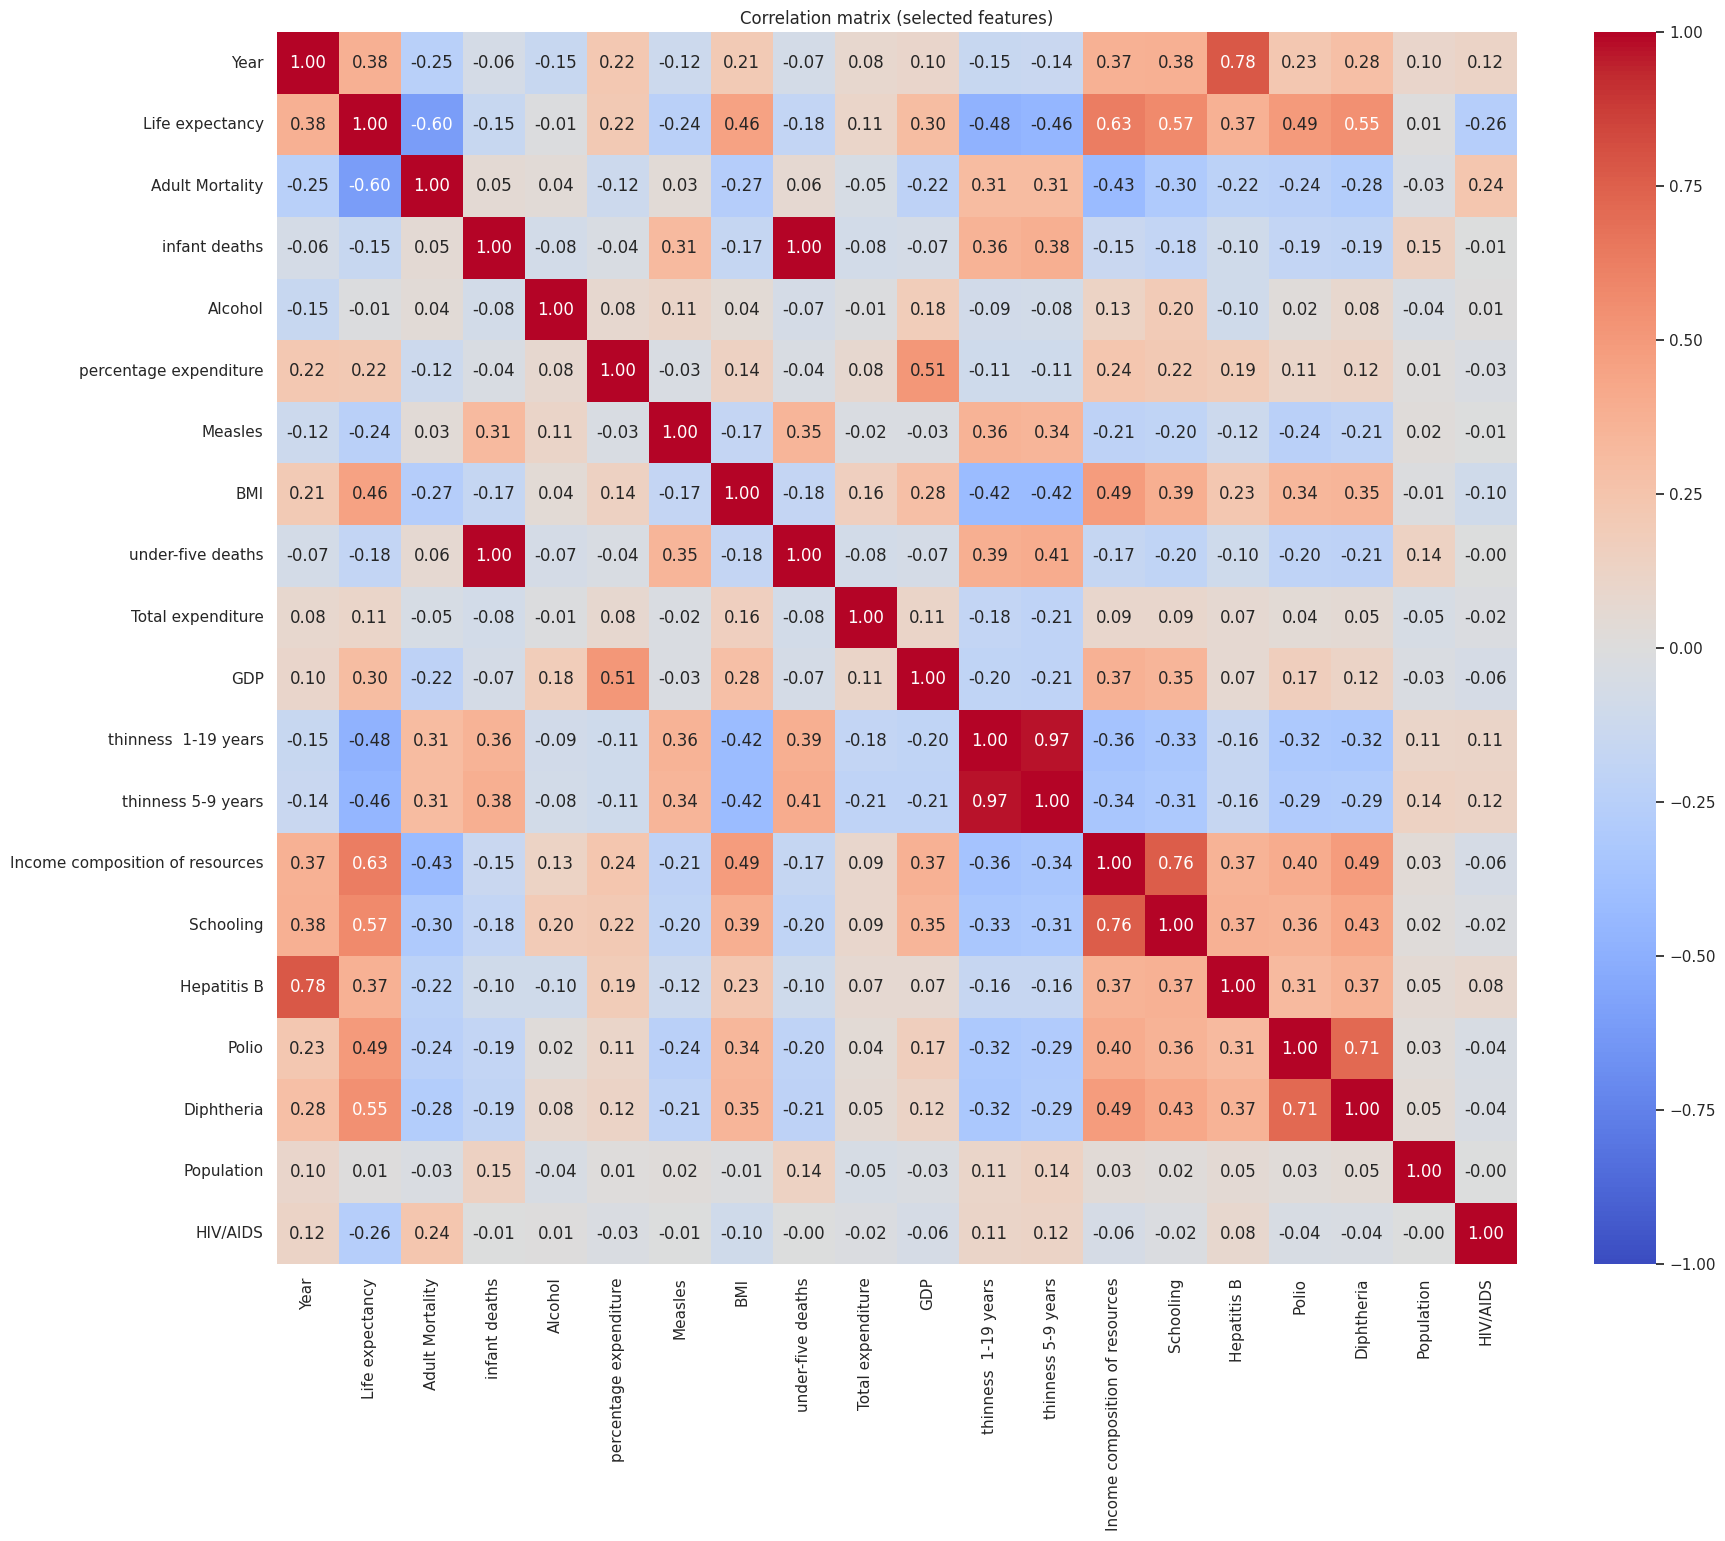

In [ ]:
# 4) Correlation heatmap for selected numeric features
# num_cols = ['Status', 'Life expectancy','Adult Mortality','infant deaths','under-five deaths','HIV/AIDS','GDP','Schooling', 'Total expenditure', 'percentage expenditure', 'Income composition of resources']
num_cols = df_eda.select_dtypes(include=[np.number]).columns.tolist()  # Automatically select numeric columns
corr_df = df_eda[num_cols].apply(pd.to_numeric, errors='coerce').corr()
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (selected features)')
plt.show()

- Pasangan kolom `infant deaths` dan `under-five deaths` serta pasangan kolom `thinness 5-9 years` dan `thinness 1-19 years` kofisien korelasinya dekat dengan satu, pertimbangkan untuk drop salah satu supaya tidak redundan. Akan tetapi, tetap ingat `correlation does not imply causation`
- Pasangan kolom `Schooling` dan `Income composition of resources` koefisien korelasinya lumayan besar (0.76), pertimbangkan untuk drop salah satu dari kedua kolom tersebut: Koefisien korelasi antara `Status` dengan `Schooling` lebih kecil dari pada dengan `Income composition of resources`, jadi, yang di-drop adalah kolom `Schooling` saja

### 2.8 Distribution of Target Variable

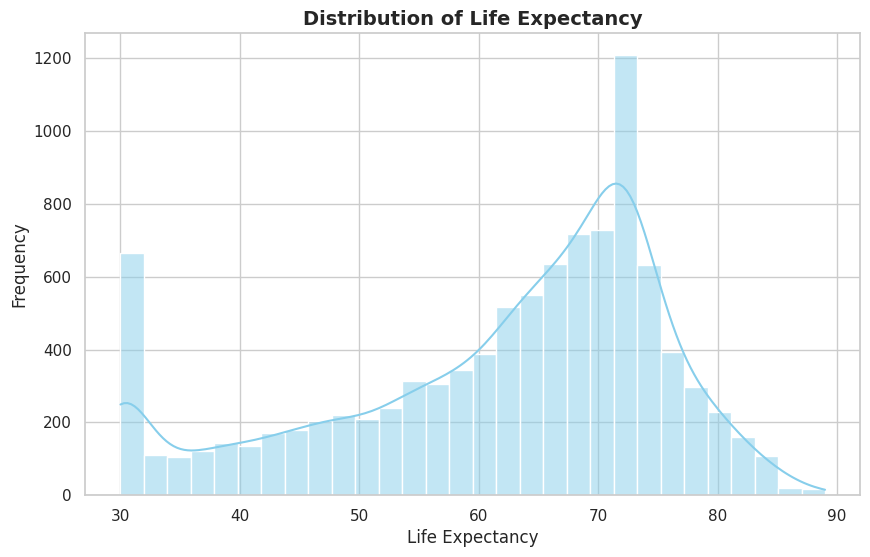

In [ ]:
# Distribusi variabel target, yaitu kolom `Life expectancy`
plt.figure(figsize=(10, 6))
sns.histplot(df_eda['Life expectancy'], bins=30, kde=True, color='skyblue', palette='Set2')
plt.title('Distribution of Life Expectancy', fontsize=14, fontweight='bold')
plt.xlabel('Life Expectancy')
plt.ylabel('Frequency')
plt.show()

## III. Data Preparation

### 3.1 Handling of Missing Values

In [ ]:
# Copy data untuk data preparation
df_prep = df_eda.copy()

# Identifikasi kolom numerik dan kategorikal
num_cols = df_prep.select_dtypes(include=[np.number]).columns.tolist()
num_cols.remove('Life expectancy')  # Exclude target variable
cat_cols = df_prep.select_dtypes(exclude=[np.number]).columns.tolist()
cat_cols.remove('Status')

print("Kolom Numerik:", num_cols)
print("Kolom Kategorikal:", cat_cols)

# Imputasi Missing Values untuk fitur numerik dengan MEDIAN
num_imputer = SimpleImputer(strategy='median')
df_prep[num_cols] = num_imputer.fit_transform(df_prep[num_cols])

# Imputasi Missing Values untuk fitur kategorikal dengan MODE (most frequent)
if cat_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    df_prep[cat_cols] = cat_imputer.fit_transform(df_prep[cat_cols])

# Verifikasi missing values
print("\nSisa Missing Values setelah imputasi:")
print(df_prep.isna().sum().sum())

Kolom Numerik: ['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']
Kolom Kategorikal: []

Sisa Missing Values setelah imputasi:
8


In [ ]:
# Fill missing values pada kolom target dengan median pada tahunnya
# Jadi, misalkan ada nilai `Life expectancy` yang hilang untuk tahun 2005, maka kita akan menggantinya dengan median `Life expectancy` dari semua data yang memiliki tahun 2005.
# Ini membantu menjaga konsistensi tren berdasarkan tahun.
# Akan tetapi, jika tidak ada data untuk tahun tertentu, kita bisa menggunakan median keseluruhan sebagai fallback.

# Impute missing values in target (Life expectancy) with median per year
# If no data for a year, use overall median as fallback

# First, get the overall median
overall_median = df_prep['Life expectancy'].median()

# Group by Year and impute
df_prep['Life expectancy'] = df_prep.groupby('Year')['Life expectancy'].transform(
    lambda x: x.fillna(x.median() if not x.dropna().empty else overall_median)
)

# Update target variable after imputation
target = df_prep['Life expectancy']

# Verify no missing values left in target
print(f"Missing values in target after imputation: {target.isna().sum()}")

Missing values in target after imputation: 0


### 3.2 Drop Duplicate Rows

In [ ]:
# Cari baris duplikat
dup_bool = df_prep.duplicated(keep=False)
dup_rows = df_prep[dup_bool]

if dup_rows.empty:
    print("Tidak ada baris duplikat di df_prep.")
else:
    # Hitung frekuensi kemunculan setiap baris duplikat
    dup_counts = (
        dup_rows
        .groupby(list(df_prep.columns), dropna=False)
        .size()
        .reset_index(name='duplicate_count')
        .sort_values('duplicate_count', ascending=False)
    )
    print("Baris duplikat dan hitungan kemunculan (termasuk aslinya):")
    display(dup_counts)

    # Drop semua duplikat (tinggalkan satu baris per set duplikat)
    original_shape = df_prep.shape
    df_prep = df_prep.drop_duplicates(keep='first').reset_index(drop=True)
    new_shape = df_prep.shape

    print(f"\nShape awal: {original_shape}")
    print(f"Shape setelah drop duplicates: {new_shape}")
    print(f"Jumlah baris dihapus: {original_shape[0] - new_shape[0]}")

Tidak ada baris duplikat di df_prep.


### 3.3 Drop `Status` and `Life expectancy` (Target Variable)
Reason: It is because the `Status` column does not exist in the test dataset

In [ ]:
# Simpan target variable (Life expectancy)
target = df_prep['Life expectancy']

# Drop `Status` karena tidak ada di test.csv
df_prep = df_prep.drop(columns=['Status', 'Life expectancy'])

### 3.4 Feature Engineering

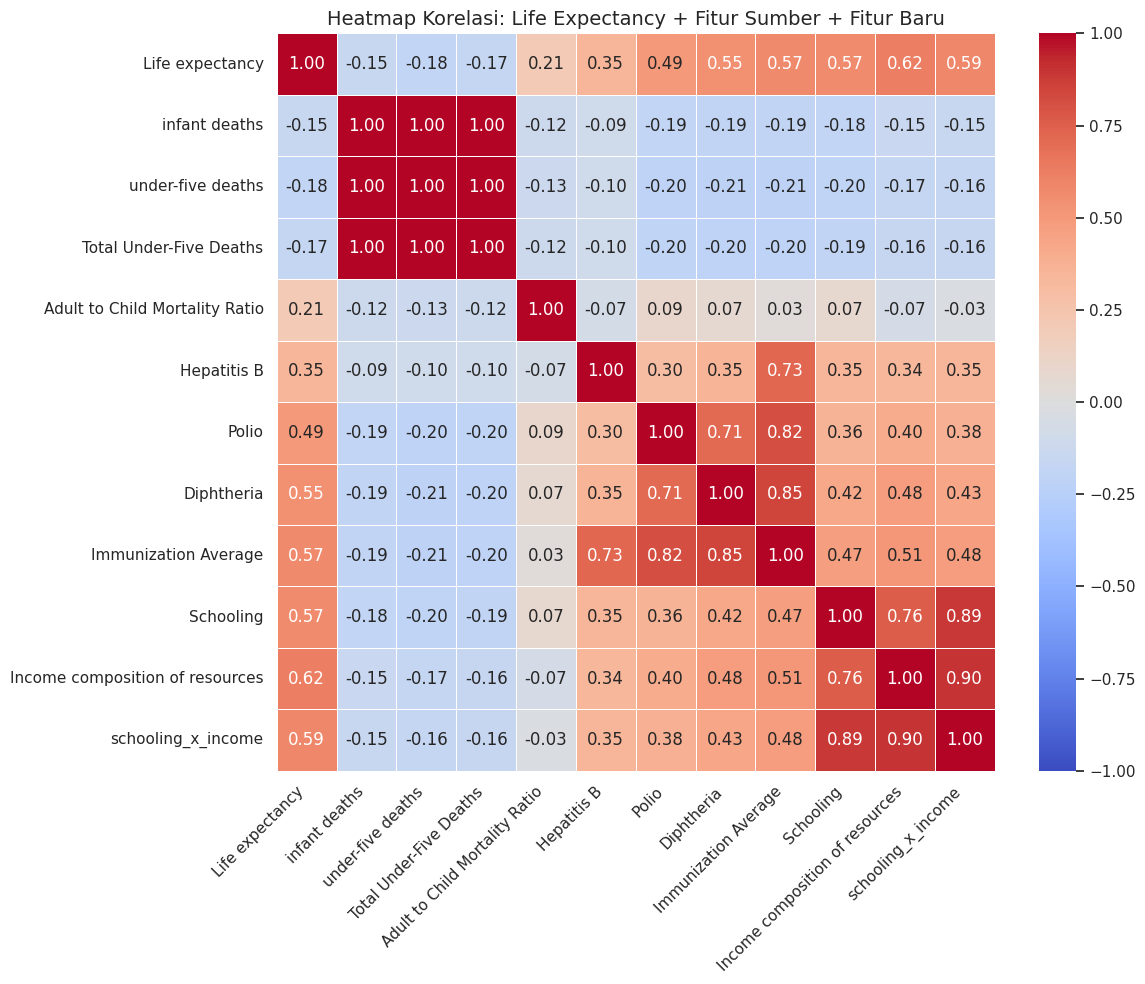

In [ ]:
# Feature Engineering pada df_prep
df_prep['Total Under-Five Deaths'] = df_prep['infant deaths'] + df_prep['under-five deaths']
df_prep['Adult to Child Mortality Ratio'] = df_prep['Adult Mortality'] / (df_prep['Total Under-Five Deaths'] + 1)  # Tambahkan 1 untuk menghindari pembagian dengan nol
df_prep['Immunization Average'] = df_prep[['Hepatitis B', 'Polio', 'Diphtheria']].mean(axis=1)
df_prep['Thinness Average'] = (df_prep['thinness  1-19 years'] + df_prep['thinness 5-9 years']) / 2
df_prep['schooling_x_income'] = df_prep['Schooling'] * df_prep['Income composition of resources']

# # Jika ingin melihat hasilnya
# display(df_prep[['infant deaths', 'under-five deaths', 'Total Under-Five Deaths',
#                  'Adult to Child Mortality Ratio', 'Hepatitis B', 'Polio', 'Diphtheria', 'Immunization Average',
#                  'Schooling', 'Income composition of resources', 'schooling_x_income']].head())

# Pastikan kolom target tersedia untuk korelasi
df_corr = df_prep.copy()
df_corr['Life expectancy'] = target.reset_index(drop=True)

# Kolom yang relevan untuk heatmap
cols_heatmap = [
    'Life expectancy',
    'infant deaths', 'under-five deaths', 'Total Under-Five Deaths',
    'Adult to Child Mortality Ratio',
    'Hepatitis B', 'Polio', 'Diphtheria', 'Immunization Average',
    'Schooling', 'Income composition of resources', 'schooling_x_income'
]

corr_mat = df_corr[cols_heatmap].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi: Life Expectancy + Fitur Sumber + Fitur Baru', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## IV. Model
### 4.1 Train the CatBoost Model

In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.6 MB/s eta 0:00:00


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor
import optuna

print("=" * 70)
print("REGRESSION MODEL TRAINING AND EVALUATION")
print("=" * 70)

# Gunakan data yang sudah di-prepare (df_prep) dan target (Life expectancy)
X_train = df_prep
y_train = target

# Split data untuk validation
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

print(f"Training set size: {X_tr.shape[0]}")
print(f"Validation set size: {X_val.shape[0]}")
print(f"Target variable statistics (training):")
print(f"  Mean: {y_tr.mean():.4f}")
print(f"  Std: {y_tr.std():.4f}")
print(f"  Min: {y_tr.min():.4f}")
print(f"  Max: {y_tr.max():.4f}")

REGRESSION MODEL TRAINING AND EVALUATION
Training set size: 8056
Validation set size: 2014
Target variable statistics (training):
  Mean: 61.6346
  Std: 14.2589
  Min: 30.0000
  Max: 89.0000


In [ ]:
# CatBoost Regressor with Hyperparameter Tuning using optuna
print("=" * 70)
print("Training CatBoost Regressor with Hyperparameter Tuning using optuna")
print("=" * 70)

print("Running optuna for CatBoost Regressor...")
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 500),
        'depth': trial.suggest_int('depth', 4, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.7, 1.0),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 1, 5),
        # 'border_count': trial.suggest_int('border_count', 32, 255),
        # 'random_strength': trial.suggest_float('random_strength', 0.0, 1.0),
        'early_stopping_rounds': trial.suggest_int('early_stopping_rounds', 10, 50)
    }
    model = CatBoostRegressor(random_state=42, verbose=0, thread_count=-1, eval_metric='R2', **params)
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='r2')
    return scores.mean()

study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(objective, n_trials=20)

# Get the best parameters from optuna
best_params_cb = study_cb.best_params

# Create a new CatBoost model with the best parameters
best_cb_model = CatBoostRegressor(random_state=42, verbose=0, thread_count=-1, eval_metric='R2', **best_params_cb)
best_cb_model.fit(X_tr, y_tr)

print(f"Best CatBoost parameters: {best_params_cb}")
print(f"Best CatBoost CV R� score: {study_cb.best_value:.4f}")

# Evaluate on validation set
y_pred_cb = best_cb_model.predict(X_val)
cb_r2 = r2_score(y_val, y_pred_cb)
cb_mse = mean_squared_error(y_val, y_pred_cb)
cb_rmse = np.sqrt(cb_mse)
cb_mae = mean_absolute_error(y_val, y_pred_cb)

print(f"\nCatBoost Validation Metrics:")
print(f"  R� Score: {cb_r2:.4f}")
print(f"  MSE: {cb_mse:.4f}")
print(f"  RMSE: {cb_rmse:.4f}")
print(f"  MAE: {cb_mae:.4f}")

Training CatBoost Regressor with Hyperparameter Tuning using optuna
Running optuna for CatBoost Regressor...
Best CatBoost parameters: {'iterations': 500, 'depth': 7, 'learning_rate': 0.07999451507664243, 'subsample': 0.8458937295156016, 'colsample_bylevel': 0.8826574726507167, 'l2_leaf_reg': 2, 'early_stopping_rounds': 23}
Best CatBoost CV R� score: 0.9858

CatBoost Validation Metrics:
  R� Score: 0.9856
  MSE: 2.8041
  RMSE: 1.6746
  MAE: 1.1534


MODEL EVALUATION SUMMARY

Best Model: CatBoost Regressor
R� Score on Validation Set: 0.9856
MAE (Mean Absolute Error): 1.1534
RMSE (Root Mean Squared Error): 1.6746

Residuals Statistics:
  Mean: 0.084912
  Std: 1.6724
  Min: -12.0569
  Max: 9.2975


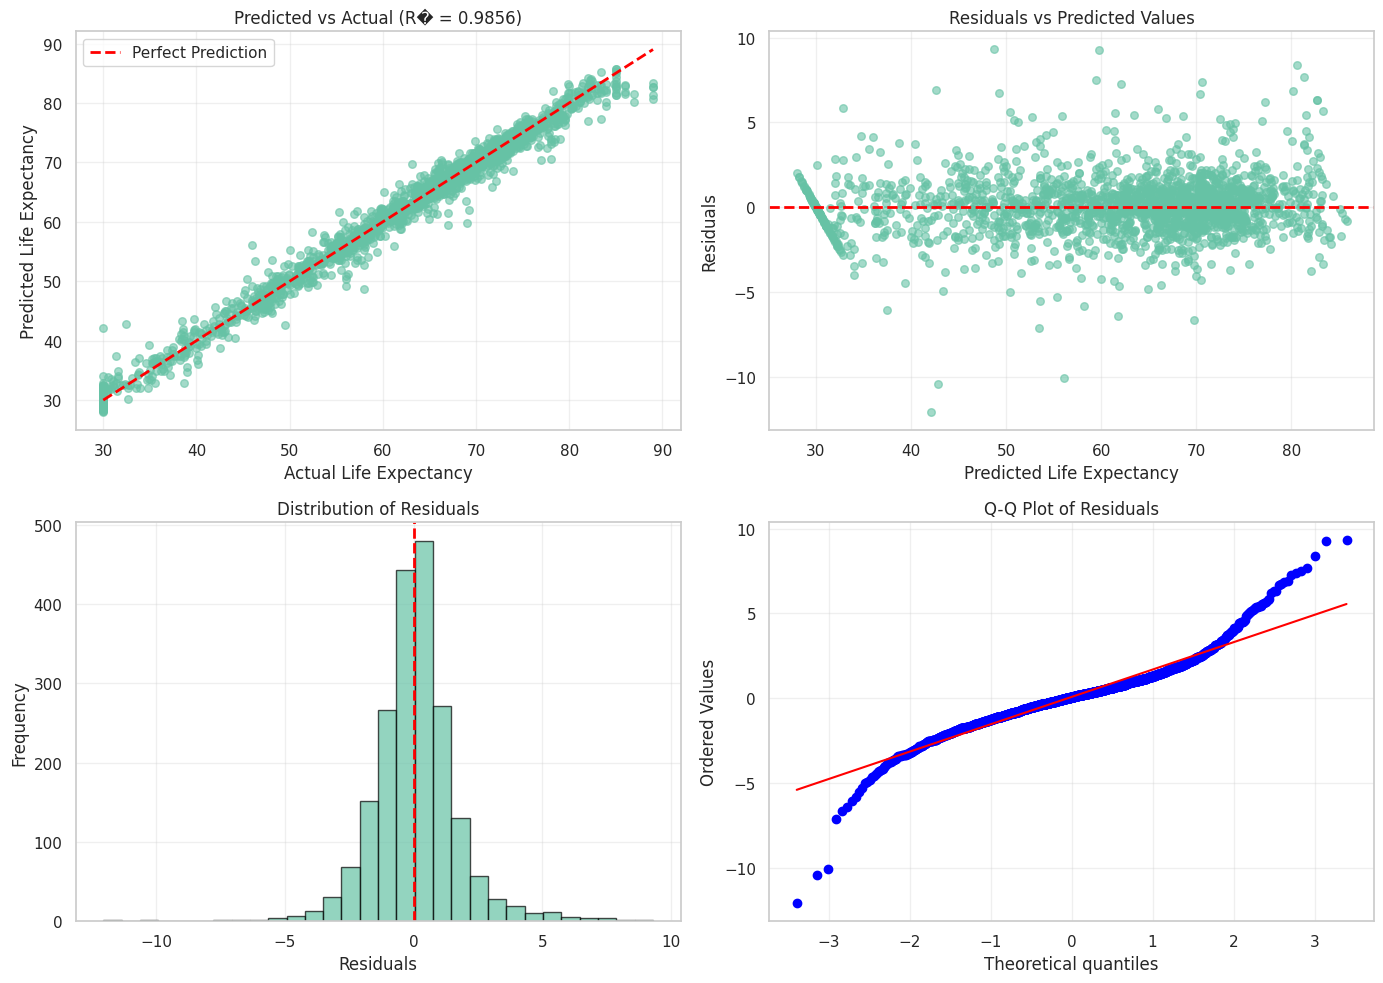

In [ ]:
print("=" * 70)
print("MODEL EVALUATION SUMMARY")
print("=" * 70)

best_model = best_cb_model
best_model_name = "CatBoost Regressor"
best_r2 = cb_r2
best_mae = cb_mae
best_rmse = cb_rmse

print(f"\nBest Model: {best_model_name}")
print(f"R� Score on Validation Set: {best_r2:.4f}")
print(f"MAE (Mean Absolute Error): {best_mae:.4f}")
print(f"RMSE (Root Mean Squared Error): {best_rmse:.4f}")

# Residuals analysis
y_pred_best = best_model.predict(X_val)
residuals = y_val.values - y_pred_best

print(f"\nResiduals Statistics:")
print(f"  Mean: {residuals.mean():.6f}")
print(f"  Std: {residuals.std():.4f}")
print(f"  Min: {residuals.min():.4f}")
print(f"  Max: {residuals.max():.4f}")

# Visualisasi: Predicted vs Actual
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Predicted vs Actual
axes[0, 0].scatter(y_val, y_pred_best, alpha=0.6, s=30)
axes[0, 0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0, 0].set_xlabel('Actual Life Expectancy')
axes[0, 0].set_ylabel('Predicted Life Expectancy')
axes[0, 0].set_title(f'Predicted vs Actual (R� = {best_r2:.4f})')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Residuals vs Predicted
axes[0, 1].scatter(y_pred_best, residuals, alpha=0.6, s=30)
axes[0, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0, 1].set_xlabel('Predicted Life Expectancy')
axes[0, 1].set_ylabel('Residuals')
axes[0, 1].set_title('Residuals vs Predicted Values')
axes[0, 1].grid(alpha=0.3)

# 3. Distribution of Residuals
axes[1, 0].hist(residuals, bins=30, edgecolor='black', alpha=0.7)
axes[1, 0].axvline(x=0, color='r', linestyle='--', lw=2)
axes[1, 0].set_xlabel('Residuals')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Residuals')
axes[1, 0].grid(alpha=0.3)

# 4. Q-Q Plot for residuals normality check
from scipy import stats as sp_stats
sp_stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot of Residuals')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Top 15 Most Important Features:
                            Feature  Importance
1                   Adult Mortality   18.439992
12  Income composition of resources   10.341152
21             Immunization Average    6.405346
3                           Alcohol    6.376786
7                 under-five deaths    5.491668
19          Total Under-Five Deaths    5.350049
22                 Thinness Average    4.306133
10             thinness  1-19 years    4.085783
5                           Measles    3.983031
20   Adult to Child Mortality Ratio    3.635001
16                       Diphtheria    3.501974
6                               BMI    3.338247
0                              Year    3.205917
13                        Schooling    2.730602
23               schooling_x_income    2.355876


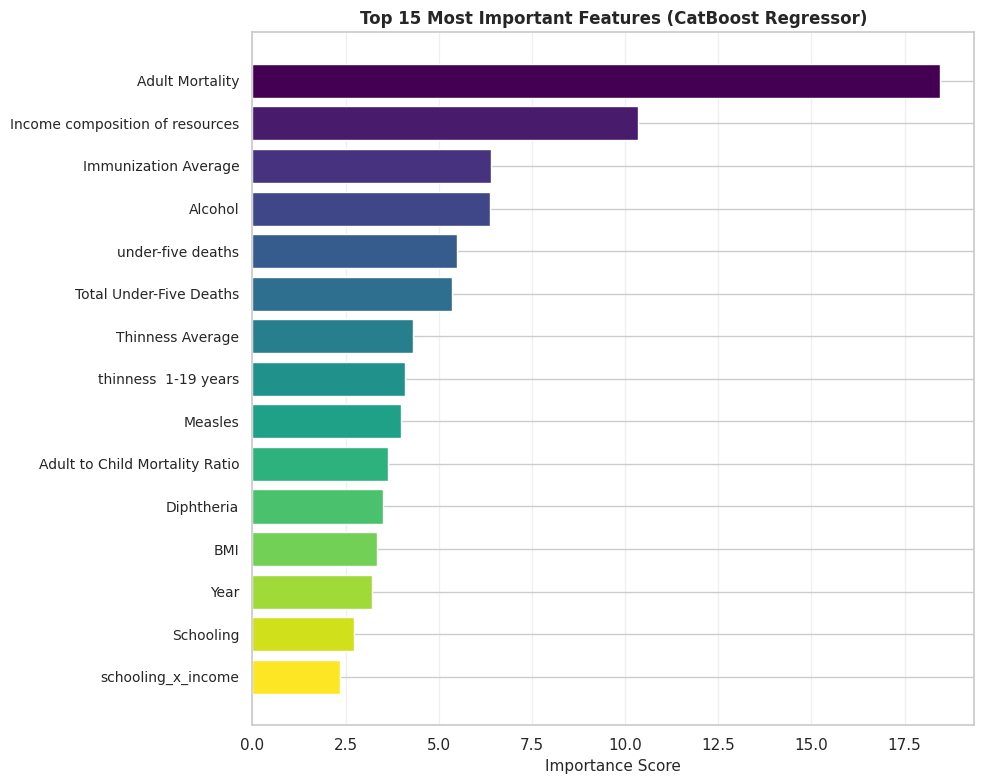

In [ ]:
# Feature Importance Analysis
importances = best_model.get_feature_importance()
feature_names = X_train.columns
features_importance = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
features_importance = features_importance.sort_values('Importance', ascending=False)

print("Top 15 Most Important Features:")
print(features_importance.head(15))

# Visualisasi Top 15 Features
fig, ax = plt.subplots(figsize=(10, 8))
top_n = 15
top_features = features_importance.head(top_n)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_features)))
ax.barh(range(len(top_features)), top_features['Importance'].values, color=colors)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'].values, fontsize=10)
ax.set_xlabel('Importance Score', fontsize=11)
ax.set_title(f'Top {top_n} Most Important Features (CatBoost Regressor)', fontsize=12, fontweight='bold')
ax.invert_yaxis()
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

In [ ]:
# Train final model pada full training data
print("=" * 70)
print("Training Final Model on Full Training Data")
print("=" * 70)

# Retrain best model pada seluruh data training
final_model = best_model
final_model.fit(X_train, y_train)

print(f"Final model ({best_model_name}) trained on full training data.")
print(f"Model configuration: {final_model.get_params()}")

# Cross-validation scores pada full data
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(final_model, X_train, y_train, cv=cv, scoring='r2')
cv_mse_scores = -cross_val_score(final_model, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')
cv_rmse_scores = np.sqrt(cv_mse_scores)

print(f"\nCross-validation R� Scores (5-fold):")
print(f"  Fold scores: {cv_scores}")
print(f"  Mean R� Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print(f"\nCross-validation RMSE Scores (5-fold):")
print(f"  Mean RMSE: {cv_rmse_scores.mean():.4f} (+/- {cv_rmse_scores.std() * 2:.4f})")

Training Final Model on Full Training Data
Final model (CatBoost Regressor) trained on full training data.
Model configuration: {'iterations': 500, 'learning_rate': 0.07999451507664243, 'depth': 7, 'l2_leaf_reg': 2, 'loss_function': 'RMSE', 'verbose': 0, 'eval_metric': 'R2', 'subsample': 0.8458937295156016, 'colsample_bylevel': 0.8826574726507167, 'random_state': 42, 'early_stopping_rounds': 23}

Cross-validation R� Scores (5-fold):
  Fold scores: [0.98593152 0.9867307  0.98803592 0.98619516 0.9865145 ]
  Mean R� Score: 0.9867 (+/- 0.0015)

Cross-validation RMSE Scores (5-fold):
  Mean RMSE: 1.6372 (+/- 0.0545)


### 4.2 Preprocess Test Data and Make Predictions Based on It

In [ ]:
# Load and preprocess test data
print("=" * 70)
print("PREPARING TEST DATA FOR PREDICTION")
print("=" * 70)

# Load test data
X_test = df_test_full.copy()

print(f"Test data shape: {X_test.shape}")
print(f"Test columns: {list(X_test.columns)}")

# Apply same preprocessing as training data

# 1. Impute missing values
test_num_cols = X_test.select_dtypes(include=[np.number]).columns.tolist()
test_cat_cols = X_test.select_dtypes(exclude=[np.number]).columns.tolist()

X_test[test_num_cols] = num_imputer.transform(X_test[test_num_cols])
if test_cat_cols:
    X_test[test_cat_cols] = cat_imputer.transform(X_test[test_cat_cols])

# 2. Feature Engineering (same as training)
X_test['Total Under-Five Deaths'] = X_test['infant deaths'] + X_test['under-five deaths']
X_test['Adult to Child Mortality Ratio'] = X_test['Adult Mortality'] / (X_test['Total Under-Five Deaths'] + 1)  # Tambahkan 1 untuk menghindari pembagian dengan nol
X_test['Immunization Average'] = X_test[['Hepatitis B', 'Polio', 'Diphtheria']].mean(axis=1)
X_test['Thinness Average'] = (X_test['thinness  1-19 years'] + X_test['thinness 5-9 years']) / 2
X_test['schooling_x_income'] = X_test['Schooling'] * X_test['Income composition of resources']

# 3. Align features with training data
X_test_final = X_test[df_prep.columns]

print(f"Preprocessed test data shape: {X_test_final.shape}")
print(f"All training features present: {all(col in X_test_final.columns for col in df_prep.columns)}")

PREPARING TEST DATA FOR PREDICTION
Test data shape: (1259, 19)
Test columns: ['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']
Preprocessed test data shape: (1259, 24)
All training features present: True


In [ ]:
# Make predictions on test data
y_test_pred = final_model.predict(X_test_final)

print(f"Predictions shape: {y_test_pred.shape}")
print(f"\nPredicted Life Expectancy Statistics:")
print(f"  Mean: {y_test_pred.mean():.4f}")
print(f"  Std: {y_test_pred.std():.4f}")
print(f"  Min: {y_test_pred.min():.4f}")
print(f"  Max: {y_test_pred.max():.4f}")
print(f"\nFirst 10 predictions:")
for i in range(min(10, len(y_test_pred))):
    print(f"  Sample {i}: {y_test_pred[i]:.4f}")

Predictions shape: (1259,)

Predicted Life Expectancy Statistics:
  Mean: 61.3660
  Std: 14.0016
  Min: 27.8391
  Max: 85.6777

First 10 predictions:
  Sample 0: 72.9656
  Sample 1: 73.0961
  Sample 2: 55.8959
  Sample 3: 33.8610
  Sample 4: 59.0813
  Sample 5: 67.3457
  Sample 6: 61.2078
  Sample 7: 75.4220
  Sample 8: 70.1123
  Sample 9: 36.7351


### 4.3 Create Output for Submission

In [ ]:
# Create submission dataframe
submission = pd.DataFrame({
    'id': range(len(y_test_pred)),
    'Life expectancy': y_test_pred
})

# Save submission
submission.to_csv('submission_catboost_regression_local_final.csv', index=False)

print("=" * 70)
print("SUBMISSION CREATED")
print("=" * 70)
print(f"Submission saved to 'submission_catboost_regression_local_final.csv'")
print(f"Submission shape: {submission.shape}")
print(f"\nFirst 10 rows of submission:")
print(submission.head(10))

print(f"\nSubmission statistics:")
print(f"  Mean Life Expectancy: {submission['Life expectancy'].mean():.4f}")
print(f"  Std Life Expectancy: {submission['Life expectancy'].std():.4f}")
print(f"  Min Life Expectancy: {submission['Life expectancy'].min():.4f}")
print(f"  Max Life Expectancy: {submission['Life expectancy'].max():.4f}")

SUBMISSION CREATED
Submission saved to 'submission_catboost_regression_local_final.csv'
Submission shape: (1259, 2)

First 10 rows of submission:
   id  Life expectancy
0   0        72.965642
1   1        73.096062
2   2        55.895948
3   3        33.861008
4   4        59.081328
5   5        67.345688
6   6        61.207817
7   7        75.422020
8   8        70.112295
9   9        36.735099

Submission statistics:
  Mean Life Expectancy: 61.3660
  Std Life Expectancy: 14.0072
  Min Life Expectancy: 27.8391
  Max Life Expectancy: 85.6777


# TP2 - Life Expectancy
## Model: XGBoost

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

eda_df = train.copy()

print("Shape train:", train.shape)
print("Shape test:", test.shape)
print("\nKolom train:")
print(train.columns.tolist())
print("\nRange Year:", train['Year'].min(), "-", train['Year'].max())
print("\nStatistik Life Expectancy:")
print(train['Life expectancy'].describe())


Shape train: (10070, 21)
Shape test: (1259, 19)

Kolom train:
['Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']

Range Year: 1950 - 2015

Statistik Life Expectancy:
count    10062.000000
mean        61.686064
std         14.203480
min         30.000000
25%         53.705956
50%         65.740650
75%         72.100000
max         89.000000
Name: Life expectancy, dtype: float64


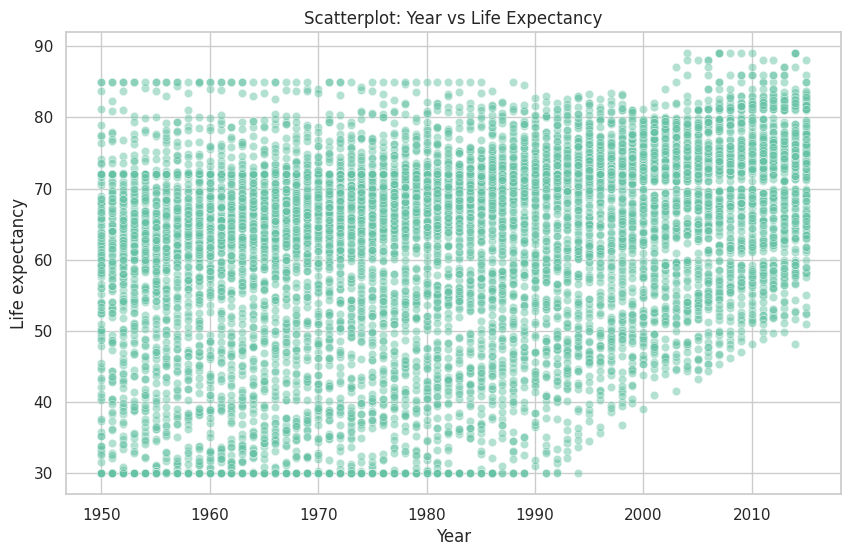

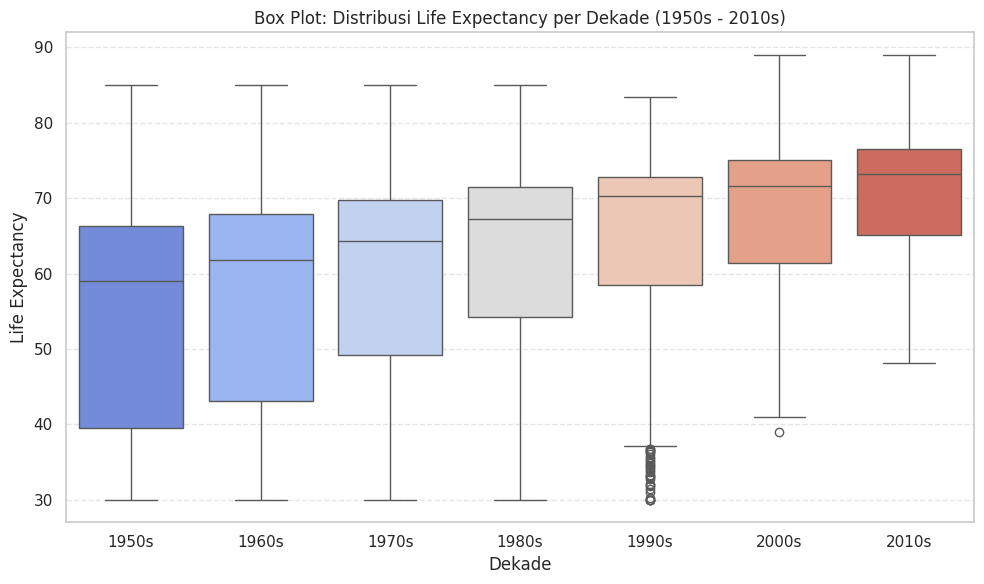

In [ ]:
# EDA: Scatterplot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=eda_df, x='Year', y='Life expectancy', alpha=0.5)
plt.title('Scatterplot: Year vs Life Expectancy')
plt.grid(True)
plt.show()

eda_df['Decade'] = ((eda_df['Year'] // 10) * 10).astype(str) + 's'

# 2. Mengurutkan data secara kronologis dari dekade tertua
eda_df = eda_df.sort_values('Year')

# 3. Membuat Box Plot per Dekade
plt.figure(figsize=(10, 6))
sns.boxplot(data=eda_df, x='Decade', y='Life expectancy', palette='coolwarm')

plt.title('Box Plot: Distribusi Life Expectancy per Dekade (1950s - 2010s)')
plt.xlabel('Dekade')
plt.ylabel('Life Expectancy')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Analisis Scatterplot
Berdasarkan visualisasi scatterplot di atas, kita dapat mengamati beberapa pola:
1. **Year vs Life Expectancy**: Terlihat ada tren peningkatan *Life Expectancy* secara global seiring berjalannya waktu (dari tahun ke tahun), meskipun sebarannya cukup luas karena perbedaan antar negara.
2. **GDP vs Life Expectancy**: Terdapat korelasi positif yang cukup jelas. Negara dengan GDP yang lebih tinggi cenderung memiliki usia harapan hidup yang jauh lebih tinggi. Titik-titik data memadat di GDP rendah dengan rentang life expectancy yang sangat variatif, namun ketika GDP mulai naik, *life expectancy* hampir selalu tinggi.
3. **Adult Mortality vs Life Expectancy**: Korelasi negatif yang sangat kuat. Semakin tinggi tingkat kematian dewasa (*adult mortality*), usia harapan hidup menurun secara drastis.
4. **BMI vs Life Expectancy**: Terdapat pengelompokan yang jelas. Negara dengan rata-rata BMI yang sangat rendah memiliki *life expectancy* yang lebih bervariasi namun cenderung lebih rendah, sedangkan kelompok negara dengan BMI sedang-tinggi lebih stabil di *life expectancy* tinggi.
5. **Schooling vs Life Expectancy**: Terdapat korelasi positif yang sangat kuat dan linear. Semakin lama masa pendidikan, semakin tinggi pula usia harapan hidup masyarakatnya.


In [ ]:
# Cek missing value
print("Missing values di TRAIN:")
print(train.isnull().sum())
print("\nMissing values di TEST:")
print(test.isnull().sum())

# Hapus baris tanpa target
train = train.dropna(subset=['Life expectancy'])

# Drop Status (Mengikuti tp2-b06-jmk48-catboost karena Status tidak ada di test)
train = train.drop(columns=['Status'], errors='ignore')
if 'Status' in test.columns:
    test = test.drop(columns=['Status'], errors='ignore')

# Pisahkan target
y = train['Life expectancy'].values
X_raw = train.drop(columns=['Life expectancy'])
test_raw = test.copy()

# Isi missing value dengan median dari train
numeric_cols = X_raw.select_dtypes(include=[np.number]).columns
medians = X_raw[numeric_cols].median()
X_raw[numeric_cols] = X_raw[numeric_cols].fillna(medians)
test_raw[numeric_cols.intersection(test_raw.columns)] = test_raw[numeric_cols.intersection(test_raw.columns)].fillna(medians)

print("\nSetelah preprocessing:")
print("Missing values train:", X_raw.isnull().sum().sum())
print("Missing values test:", test_raw.isnull().sum().sum())
print("Shape X:", X_raw.shape)


Missing values di TRAIN:
Year                                 0
Status                               0
Life expectancy                      8
Adult Mortality                      8
infant deaths                        0
Alcohol                            150
percentage expenditure               0
Measles                              0
BMI                                 23
under-five deaths                    0
Total expenditure                  176
GDP                                363
thinness  1-19 years                23
thinness 5-9 years                  23
Income composition of resources    140
Schooling                          137
Hepatitis B                        456
Polio                               13
Diphtheria                          13
Population                         527
HIV/AIDS                             0
dtype: int64

Missing values di TEST:
Year                                0
Adult Mortality                     0
infant deaths                       0
Alco

In [ ]:
def add_features(df):
    """Tambahkan fitur-fitur baru dan outlier handling untuk meningkatkan performa model"""
    df = df.copy()

    # 1. Outlier Capping & Log transform untuk fitur finansial/skewed
    # Capping pada persentil 99 agar model robust
    for col in ['GDP', 'percentage expenditure', 'Population', 'Total expenditure']:
        if col in df.columns:
            upper_limit = df[col].quantile(0.99)
            # Clip outlier ke batas atas
            df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])
            # Log transform
            df[f'log_{col}'] = np.log1p(df[col].clip(lower=0))

    # 2. Interaksi antar fitur penting
    df['Adult_Mortality_x_HIV'] = df['Adult Mortality'] * df['HIV/AIDS']
    df['Schooling_x_Income'] = df['Schooling'] * df['Income composition of resources']
    df['BMI_x_Alcohol'] = df['BMI'] * df['Alcohol']
    df['GDP_x_Schooling'] = df['GDP'] * df['Schooling']

    # 3. Rasio fitur
    df['mortality_ratio'] = df['Adult Mortality'] / (df['infant deaths'] + 1)
    df['child_mortality_ratio'] = df['under-five deaths'] / (df['infant deaths'] + 1)
    df['thinness_ratio'] = df['thinness  1-19 years'] / (df['thinness 5-9 years'] + 0.01)
    df['immunization_avg'] = (df['Polio'] + df['Diphtheria'] + df['Hepatitis B']) / 3

    # 4. Polynomial features
    df['Schooling_sq'] = df['Schooling'] ** 2
    df['Income_sq'] = df['Income composition of resources'] ** 2
    df['Adult_Mortality_sq'] = df['Adult Mortality'] ** 2
    df['HIV_sq'] = df['HIV/AIDS'] ** 2

    # 5. Year-based features
    df['Year_since_1950'] = df['Year'] - 1950
    df['Year_sq'] = df['Year_since_1950'] ** 2

    # 6. Composite health index
    df['health_index'] = (df['BMI'] + df['Schooling'] * 3 +
                          df['Income composition of resources'] * 100 -
                          df['Adult Mortality'] * 0.1 - df['HIV/AIDS'] * 5)

    return df

# Terapkan feature engineering
X = add_features(X_raw)
test_features = add_features(test_raw)

# Selaraskan kolom test dengan train
for col in X.columns:
    if col not in test_features.columns:
        test_features[col] = 0
test_features = test_features[X.columns]

# Isi NaN tersisa
X = X.fillna(0)
test_features = test_features.fillna(0)

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print(f"\nTotal fitur: {X.shape[1]} (asli + engineered)")


Shape X: (10062, 38)
Shape y: (10062,)

Total fitur: 38 (asli + engineered)


In [ ]:
import optuna
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# Fungsi objective untuk Optuna
def objective(trial):
    # Ruang pencarian hyperparameter
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 3000),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'random_state': 42,
        'n_jobs': -1
    }

    n_folds = 5 # cross-val untuk objective function
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)

    rmse_scores = []

    for train_idx, val_idx in kf.split(X):
        X_tr = X.iloc[train_idx]
        y_tr = y[train_idx]
        X_vl = X.iloc[val_idx]
        y_vl = y[val_idx]

        model = XGBRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)], verbose=0)

        preds = model.predict(X_vl)
        rmse = np.sqrt(mean_squared_error(y_vl, preds))
        rmse_scores.append(rmse)

    return np.mean(rmse_scores)

print("Memulai Optuna Hyperparameter Tuning dengan 20 trials...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=20)

print("Best trial:")
trial = study.best_trial
print(f"  Value (RMSE): {trial.value}")
print("  Params: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

# Gunakan hyperparameter terbaik
best_params = trial.params
best_params['random_state'] = 42
best_params['n_jobs'] = -1

# K-Fold = 15 untuk final training
n_folds = 15
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)

oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(test_features))
fold_scores = []

print(f"\nTraining XGBoost Final dengan {n_folds}-Fold Ensemble")
print("=" * 60)

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    X_tr = X.iloc[train_idx]
    y_tr = y[train_idx]
    X_vl = X.iloc[val_idx]
    y_vl = y[val_idx]

    model = XGBRegressor(**best_params)

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        verbose=0
    )

    oof_preds[val_idx] = model.predict(X_vl)
    test_preds += model.predict(test_features) / n_folds

    fold_r2 = r2_score(y_vl, oof_preds[val_idx])
    fold_rmse = np.sqrt(mean_squared_error(y_vl, oof_preds[val_idx]))
    fold_scores.append(fold_r2)
    print(f"  Fold {fold+1:2d}: R2 = {fold_r2:.6f} | RMSE = {fold_rmse:.4f}")

overall_r2 = r2_score(y, oof_preds)
overall_rmse = np.sqrt(mean_squared_error(y, oof_preds))
print("=" * 60)
print(f"Overall OOF R2:   {overall_r2:.6f}")
print(f"Overall OOF RMSE: {overall_rmse:.4f}")
print(f"Mean Fold R2:     {np.mean(fold_scores):.6f} (+/- {np.std(fold_scores):.6f})")

Memulai Optuna Hyperparameter Tuning dengan 20 trials...
Best trial:
  Value (RMSE): 1.4057812090793544
  Params: 
    n_estimators: 1710
    max_depth: 10
    learning_rate: 0.010491062388176561
    subsample: 0.7951296450743055
    colsample_bytree: 0.663552367839347
    colsample_bylevel: 0.7192663151061942
    reg_alpha: 0.04971325698714139
    reg_lambda: 2.8422254791543156e-05
    min_child_weight: 6
    gamma: 5.612246288014965e-06

Training XGBoost Final dengan 15-Fold Ensemble
  Fold  1: R2 = 0.991673 | RMSE = 1.3305
  Fold  2: R2 = 0.988817 | RMSE = 1.4530
  Fold  3: R2 = 0.991848 | RMSE = 1.2897
  Fold  4: R2 = 0.992595 | RMSE = 1.2598
  Fold  5: R2 = 0.989680 | RMSE = 1.3764
  Fold  6: R2 = 0.992124 | RMSE = 1.2779
  Fold  7: R2 = 0.992191 | RMSE = 1.2510
  Fold  8: R2 = 0.989361 | RMSE = 1.4365
  Fold  9: R2 = 0.992528 | RMSE = 1.3121
  Fold 10: R2 = 0.991589 | RMSE = 1.2747
  Fold 11: R2 = 0.991863 | RMSE = 1.2900
  Fold 12: R2 = 0.992090 | RMSE = 1.2791
  Fold 13: R2 = 0

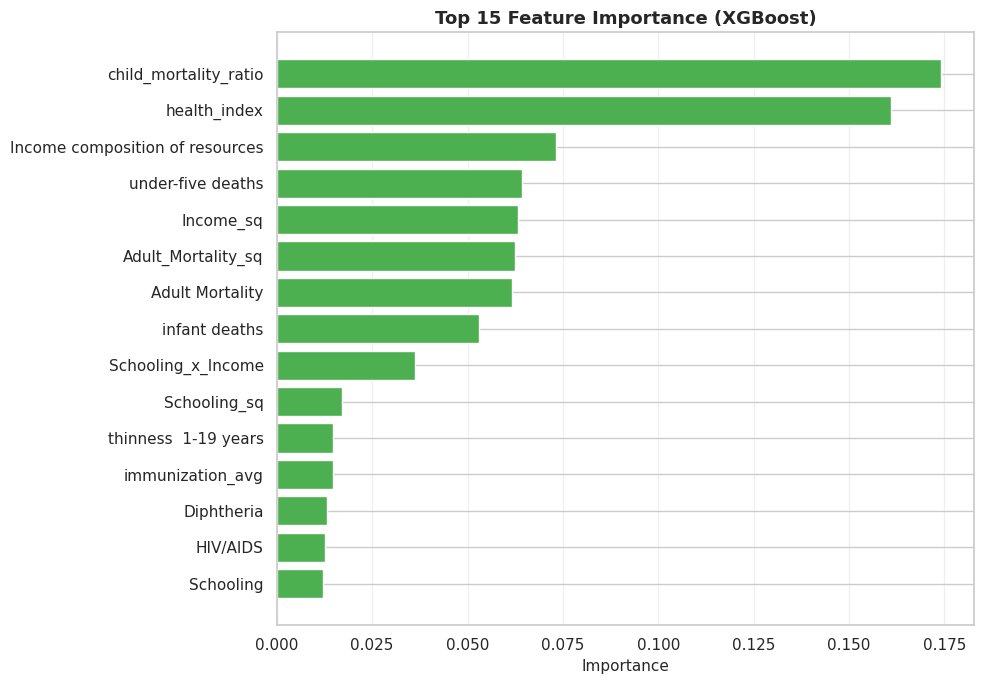

In [ ]:
# Feature Importance (dari model terakhir)
importances = model.feature_importances_
feat_imp = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feat_imp = feat_imp.sort_values('Importance', ascending=True).tail(15)

plt.figure(figsize=(10, 7))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='#4CAF50')
plt.xlabel('Importance', fontsize=11)
plt.title('Top 15 Feature Importance (XGBoost)', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


In [ ]:
# Output prediksi test set
print("Jumlah prediksi:", len(test_preds))
print("\nStatistik prediksi:")
print(pd.Series(test_preds).describe())

submission = pd.DataFrame({
    "id": range(len(test_preds)),
    "Predicted_Life_Expectancy": test_preds
})

submission.to_csv("submission2_regression.csv", index=False)

print("\nFile submission_regression.csv berhasil disimpan!")
print("\nPreview:")
print(submission.head(10))


Jumlah prediksi: 1259

Statistik prediksi:
count    1259.000000
mean       61.350258
std        13.950610
min        29.600386
25%        53.245173
50%        65.187942
75%        72.058925
max        84.948779
dtype: float64

File submission_regression.csv berhasil disimpan!

Preview:
   id  Predicted_Life_Expectancy
0   0                  73.270609
1   1                  72.209280
2   2                  56.924968
3   3                  33.601449
4   4                  56.906491
5   5                  65.968868
6   6                  60.584451
7   7                  75.617965
8   8                  69.477624
9   9                  36.047092


# TP2 - Life Expectancy Regression
## Random Forest Regression Model

**Objective:** Predict `Life Expectancy` (a continuous numeric value) using a **regression** model evaluated by **R^2** score.

**Submission format:** `id, Life Expectancy`

## Step 1: Load Data & Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import optuna
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
# Load the datasets
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (10070, 21)
Test shape: (1259, 19)


## Step 2: Data Exploration (EDA)

In [ ]:
# Quick look at the data
print(train_df.head())
print()
train_df.info()
print()
train_df.describe().T

   Year      Status  Life expectancy  Adult Mortality  infant deaths  \
0  1967   Developed        75.958705        30.409030              7   
1  1990  Developing        42.915277       101.499444             18   
2  1974  Developing        49.322096       209.702245             81   
3  1970  Developing        30.000000       452.548059            168   
4  2010  Developing        61.800000       261.000000            162   

     Alcohol  percentage expenditure  Measles        BMI  under-five deaths  \
0  16.891705              100.000000    77790   7.022069                 10   
1   8.230195                0.000000     2106   5.000000                 28   
2   0.010000                0.000000        0  30.193667                108   
3   5.347899                0.000000    29763  10.879758                298   
4   1.340000               67.733744     4235  15.600000                243   

   ...           GDP  thinness  1-19 years  thinness 5-9 years  \
0  ...  79835.055962      

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


In [ ]:
# Missing values analysis
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)

missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False))

                                 Missing Count  Missing %
Population                                 527       5.23
Hepatitis B                                456       4.53
GDP                                        363       3.60
Total expenditure                          176       1.75
Alcohol                                    150       1.49
Income composition of resources            140       1.39
Schooling                                  137       1.36
thinness  1-19 years                        23       0.23
BMI                                         23       0.23
thinness 5-9 years                          23       0.23
Polio                                       13       0.13
Diphtheria                                  13       0.13
Life expectancy                              8       0.08
Adult Mortality                              8       0.08


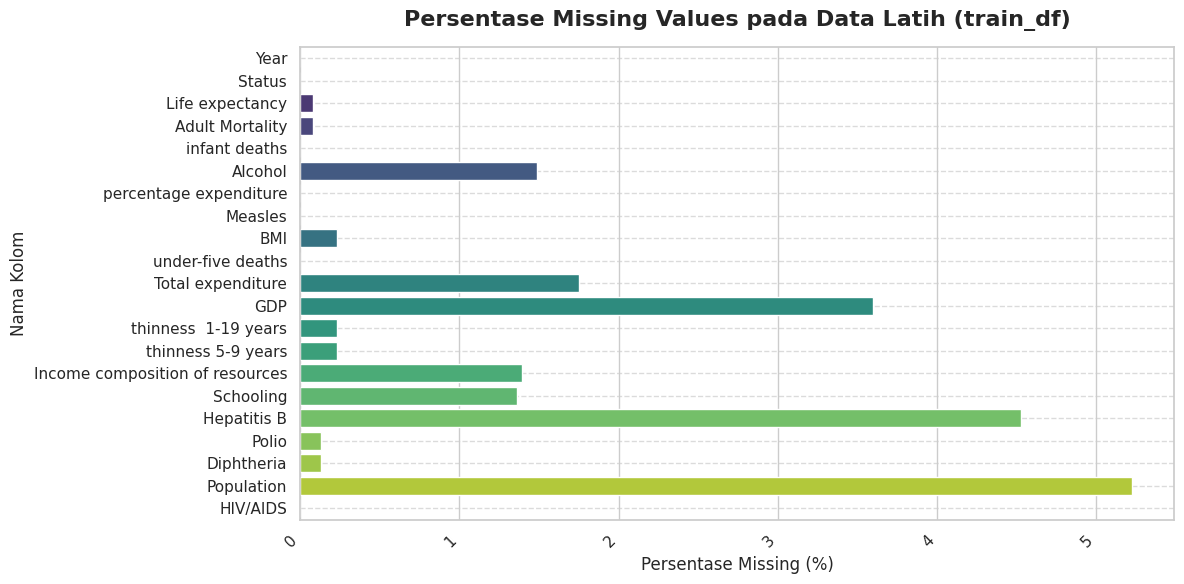

In [ ]:
plt.figure(figsize=(12, 6)) # Mengatur ukuran gambar

# Menggunakan Seaborn untuk membuat bar chart vertikal
sns.barplot(
    x=missing_pct,
    y=missing.index,
    orient='h', # Membuat bar horizontal
    palette="viridis" # Pilihan warna
)

# Menyesuaikan label dan rotasi sumbu X agar tidak saling tumpang tindih
plt.xticks(rotation=45, ha='right')

# Menambahkan judul dan label sumbu
plt.title('Persentase Missing Values pada Data Latih (train_df)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Persentase Missing (%)', fontsize=12)
plt.ylabel('Nama Kolom', fontsize=12)

# Menambahkan grid agar lebih mudah mengira-ngira nilai
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mengatur layout agar rapi dan menampilkan plot
plt.tight_layout()
plt.show()

## Kondisi Data Secara Keseluruhan Sangat Baik

Dataset memiliki kualitas kelengkapan yang sangat bagus. Jika diperhatikan sumbu X (Persentase Missing), nilai tertingginya hanya berada di kisaran angka **5%**. Ini berarti tidak ada kolom yang mengalami krisis data. Tidak perlu menghapus/membuang (drop) kolom mana pun dari dataset ini.

## Identifikasi & Tindakan Berdasarkan Kategori

Bisa dibagi kolom-kolom ini ke dalam beberapa kelompok tindakan:

#### Batas Menengah - Rendah (Sekitar 4% - 5.5%)

Kolom:
- Population (tertinggi, ~5.3%)
- Hepatitis B (~4.6%).

Tindakan:

Karena nilainya mendekati batas 5%, membuang baris (drop rows) mungkin akan menghilangkan lumayan banyak sampel (sekitar 5% dari total data). Bisa dilakukan imputasi sederhana. Jika distribusinya normal, gunakan Mean (rata-rata). Jika datanya memiliki banyak outlier (pencilan), gunakan Median (nilai tengah).

#### Sangat Rendah (Di bawah 4%)

Kolom:
- GDP (~3.6%)
- Total expenditure (~1.8%)
- Alcohol
- Income composition of resources
- Schooling, dan beberapa lainnya

Tindakan:

Persentase data yang hilang sangat tidak signifikan. Bisa dengan aman mengisi nilai yang kosong dengan Mean atau Median tanpa takut merusak pola asli dari dataset. Alternatif lain, menghapus baris (drop rows) untuk kolom yang nilai missing-nya di bawah 1% juga tidak terlalu berdampak.

#### Data Lengkap (0% Missing)

Kolom:
- Year
- Status
- infant deaths
- percentage expenditure
- Measles
- under-five deaths
- HIV/AIDS.

Interpretasi:

Kolom-kolom yang tidak memiliki batang (bar) pada grafik ini berarti datanya 100% lengkap dan siap digunakan langsung untuk pemodelan.

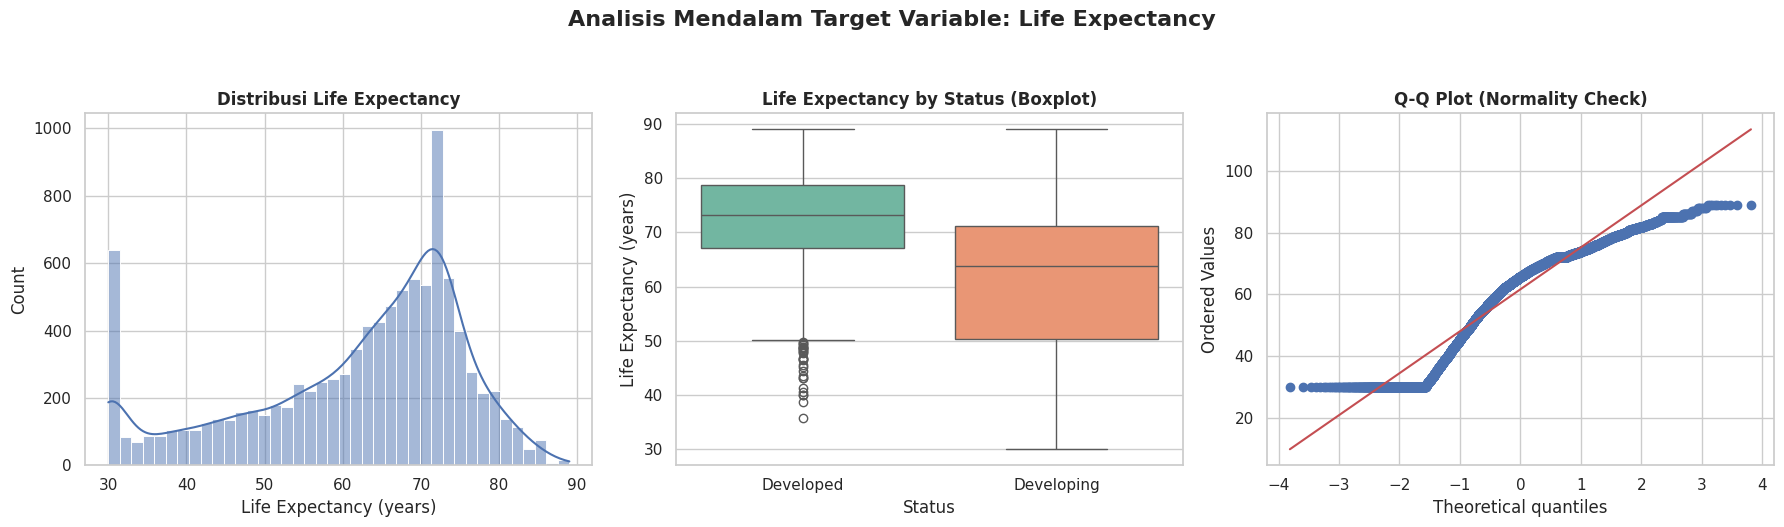

--- Statistik Deskriptif Target Variable ---
Mean (Rata-rata): 61.69
Median (Nilai Tengah): 65.74
Standar Deviasi : 14.20
Min  : 30.00
Max  : 89.00
Skewness : -0.81
Kurtosis : -0.23


In [ ]:
# Mengatur gaya seaborn agar lebih rapi
sns.set_theme(style="whitegrid")

# Menyiapkan figure dengan 3 subplot (1 baris, 3 kolom)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram + KDE (Distribusi Keseluruhan)
sns.histplot(train_df["Life expectancy"].dropna(), bins=40, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Distribusi Life Expectancy", fontweight="bold")
axes[0].set_xlabel("Life Expectancy (years)")

# 2. Box Plot (Deteksi Outlier & Perbandingan Status)
# Ini akan menggantikan "layered histogram" Anda menjadi perbandingan yang lebih jelas
sns.boxplot(x="Status", y="Life expectancy", data=train_df, palette="Set2", ax=axes[1])
axes[1].set_title("Life Expectancy by Status (Boxplot)", fontweight="bold")
axes[1].set_ylabel("Life Expectancy (years)")

# 3. Q-Q Plot (Uji Normalitas)
stats.probplot(train_df["Life expectancy"].dropna(), dist="norm", plot=axes[2])
axes[2].set_title("Q-Q Plot (Normality Check)", fontweight="bold")

plt.suptitle("Analisis Mendalam Target Variable: Life Expectancy", fontsize=16, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

# --- Print Statistik Deskriptif ---
target = train_df['Life expectancy'].dropna()

print("--- Statistik Deskriptif Target Variable ---")
print(f"Mean (Rata-rata): {target.mean():.2f}")
print(f"Median (Nilai Tengah): {target.median():.2f}")
print(f"Standar Deviasi : {target.std():.2f}")
print(f"Min  : {target.min():.2f}")
print(f"Max  : {target.max():.2f}")
print(f"Skewness : {target.skew():.2f}")
print(f"Kurtosis : {target.kurt():.2f}")

**Temuan Paling Kritis: Anomali di Angka 30**

Ada satu anomali besar yang harus segera mendapat perhatian, yakni adanya lonjakan data yang sangat tidak wajar di angka 30.

Pada Histogram, terlihat satu batang (bar) paling kiri yang menjulang sangat tinggi secara tidak natural.

Pada Q-Q Plot, titik-titik biru di bagian bawah kiri membentuk garis horizontal datar yang sangat kaku tepat di sumbu Y=30.

Interpretasi:

Ini biasanya bukan data alami. Kemungkinan besar angka 30 ini adalah hasil dari hard-capping (batas bawah buatan), atau yang paling sering terjadi: imputasi nilai kosong yang kurang tepat. Jika data yang missing sebelumnya diisi secara massal dengan angka 30, hal ini akan merusak distribusi asli data. Ini perlu diinvestigasi lebih lanjut sebelum masuk ke tahap pemodelan.

1. Analisis Distribusi (Histogram & Statistik)

Bentuk Distribusi (Skewness): Distribusi data Anda condong ke kiri (Left-Skewed atau Negative Skew).

Secara visual, ekor kurva (KDE) memanjang ke sebelah kiri.

Secara statistik, ini dibuktikan kuat oleh Mean (61.69) < Median (65.74) dan nilai Skewness (-0.81).

Pemusatan Data: Mayoritas usia harapan hidup terpusat di rentang yang cukup tinggi, yaitu sekitar 60 hingga 80 tahun. Kematian di usia yang lebih muda menarik rata-rata (Mean) menjadi lebih rendah daripada nilai tengahnya (Median).

Kurtosis (-0.23): Nilainya mendekati nol namun sedikit negatif, yang berarti puncak kurvanya sedikit lebih datar dibandingkan distribusi normal sempurna (platykurtic), meskipun perbedaannya tidak terlalu ekstrem.

2. Perbandingan Kategori: Developed vs Developing (Boxplot)

Boxplot memberikan wawasan yang sangat jelas mengenai kesenjangan antar status negara:

Negara Maju (Developed): Memiliki nilai median harapan hidup yang jauh lebih tinggi (sekitar pertengahan 70-an). Kotaknya lebih sempit, yang berarti variansi atau sebaran datanya lebih seragam. Namun, ada cukup banyak outlier di bagian bawah (titik-titik lingkaran), yang menunjukkan ada kondisi khusus di beberapa negara maju yang membuat harapan hidupnya anjlok.

Negara Berkembang (Developing): Memiliki median yang jauh lebih rendah (di kisaran 60-an). Kotaknya jauh lebih tinggi/lebar, yang mengindikasikan ketimpangan yang besar; ada negara berkembang dengan harapan hidup yang sudah cukup baik, namun banyak juga yang masih sangat buruk.

3. Uji Normalitas (Q-Q Plot)

Interpretasi: Target variabel tidak terdistribusi normal.

Titik-titik observasi (biru) melenceng jauh dari garis diagonal teoretis (merah). Penyimpangan terparah terjadi di bagian ekor bawah (karena anomali angka 30 tadi) dan sedikit melengkung di bagian ekor atas.

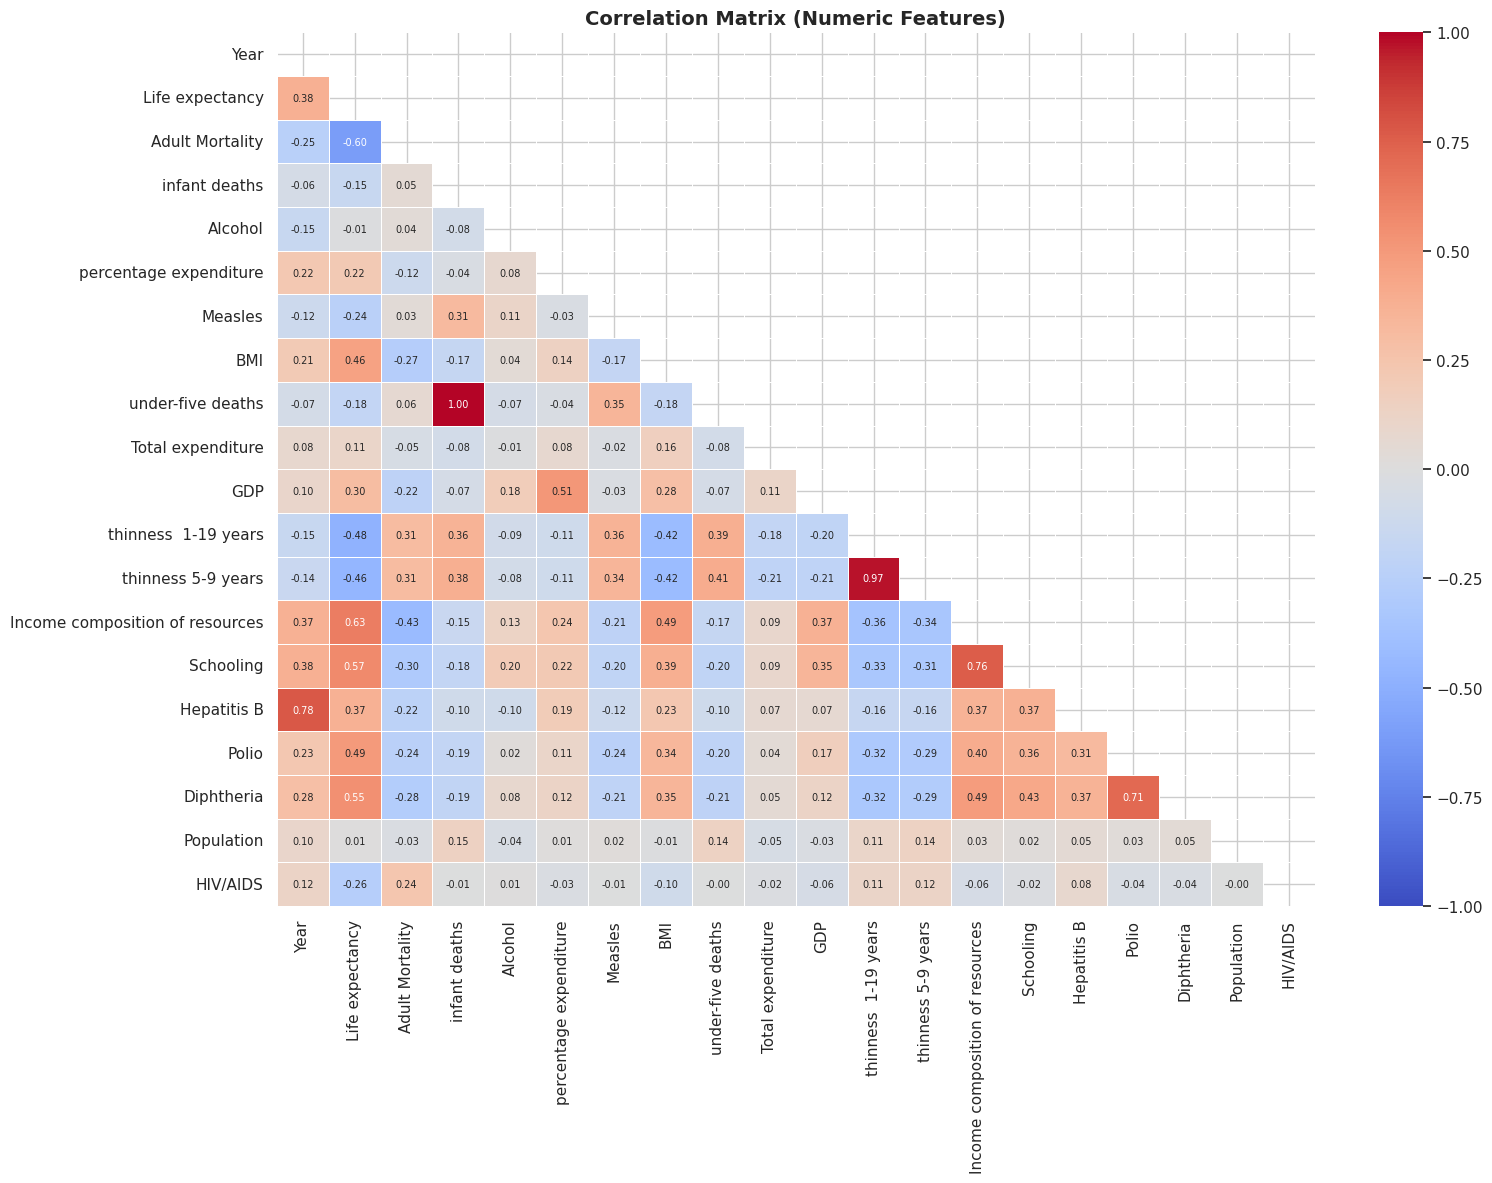

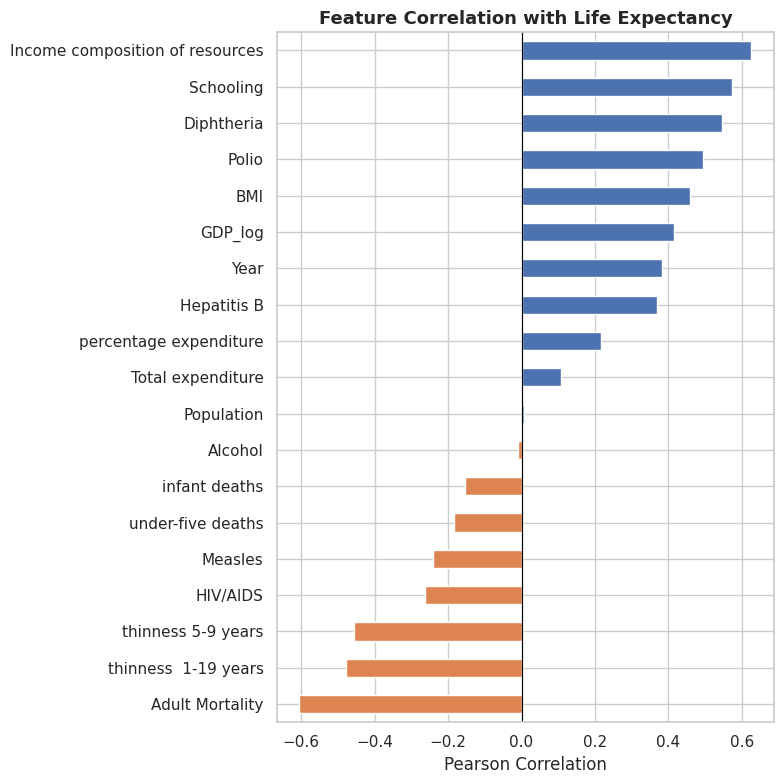

In [ ]:
# Correlation heatmap (numeric features)
num_cols = train_df.select_dtypes(include=np.number).columns.tolist()

fig, ax = plt.subplots(figsize=(16, 12))
corr = train_df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap="coolwarm",
            linewidths=0.5, linecolor="white", ax=ax,
            annot_kws={"size": 7}, vmin=-1, vmax=1)
ax.set_title("Correlation Matrix (Numeric Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Correlation with target: Life Expectancy
train_df["GDP_log"] = np.log1p(train_df["GDP"])
num_cols_updated = train_df.select_dtypes(include=[np.number]).columns.tolist()
if "GDP" in num_cols_updated:
    num_cols_updated.remove("GDP")
corr_with_target = train_df[num_cols_updated].corr()["Life expectancy"].drop("Life expectancy").sort_values()

plt.figure(figsize=(8, 8))
colors = ["#DD8452" if v < 0 else "#4C72B0" for v in corr_with_target.values]
corr_with_target.plot(kind="barh", color=colors, edgecolor="white")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlation with Life Expectancy", fontsize=13, fontweight="bold")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

#### 1. Faktor Penentu Harapan Hidup (Korelasi dengan Life expectancy)

Fokus pertama adalah melihat baris/kolom Life expectancy untuk mengetahui fitur mana saja yang memiliki daya tarik terkuat:

Pendorong Positif Utama: Income composition of resources (0.63) dan Schooling (0.57) memiliki korelasi positif terkuat. Sangat logis mengingat negara dengan alokasi pendapatan masyarakat yang baik dan akses pendidikan yang lebih lama berbanding lurus dengan tingginya usia harapan hidup. Selain itu, tingkat cakupan imunisasi seperti Diphtheria (0.55) dan Polio (0.49) juga berdampak positif secara signifikan.

Penarik Negatif Utama: Adult Mortality (-0.60) adalah faktor penurun harapan hidup yang paling kuat, disusul oleh masalah gizi buruk/kekurusan, yaitu thinness 1-19 years (-0.48) dan thinness 5-9 years (-0.46).

#### 2. Peringatan Kritis: Isu Multikolinearitas Ekstrem

Multicollinearity (multikolinearitas) terjadi ketika dua fitur independent (variabel X) saling berkorelasi sangat kuat. Ini adalah "musuh bebuyutan" bagi model seperti Regresi Linear karena model akan kesulitan menentukan fitur mana yang sebenarnya memberikan dampak pada target (terjadi redundansi informasi). Di dataset, isu ini sangat menonjol:

- **infant deaths dan under-five deaths (Korelasi 1.00):** Ini adalah korelasi positif sempurna. Kedua fitur ini pada dasarnya menceritakan hal yang persis sama kepada model Anda.

Tindakan: Wajib membuang (drop) salah satu dari kolom tersebut.

- **thinness 1-19 years dan thinness 5-9 years (Korelasi 0.97):** Korelasinya nyaris sempurna karena rentang usianya saling tumpang tindih secara data.

Tindakan: Buang salah satu fiturnya. Sebaiknya pertahankan thinness 1-19 years karena korelasinya terhadap target (Life expectancy) sedikit lebih tinggi dibandingkan yang usia 5-9 tahun.

#### 3. Wawasan Antar-Fitur (Inter-feature Correlation)
Melihat hubungan antar variabel independen juga memberikan pemahaman tentang kondisi global di dataset ini:

- Pendidikan & Ekonomi: Schooling dan Income composition of resources berkorelasi tinggi (0.76). Ini menunjukkan realitas bahwa sistem pendidikan yang maju sering kali berjalan beriringan dengan tingkat ekonomi yang mapan. Keduanya mungkin merepresentasikan "Tingkat Kemajuan Negara".

- Paket Imunisasi: Polio dan Diphtheria berkorelasi tinggi (0.71). Artinya, jika sebuah negara memiliki infrastruktur kesehatan yang mampu mendistribusikan vaksin Polio dengan baik, kemungkinan besar mereka juga sukses mendistribusikan vaksin Difteri.

- Anomali Variabel Waktu: Kolom Year memiliki korelasi yang sangat tinggi dengan Hepatitis B (0.78). Ini adalah anomali yang menarik. Hal ini bisa berarti dua hal: cakupan vaksin Hepatitis B memang meledak drastis dari tahun ke tahun, atau banyak data Hepatitis B yang kosong (missing) di tahun-tahun awal pencatatan sehingga polanya terlihat miring ke tahun-tahun terbaru.

Kesimpulan Tindakan:
Berdasarkan EDA ini, sekarang terdapat justifikasi berbasis data yang kuat untuk melakukan seleksi fitur (Feature Selection). Membuang fitur yang redundan (seperti infant deaths dan thinness 5-9 years) tidak hanya akan meringankan beban komputasi, tetapi juga akan meningkatkan stabilitas dan akurasi model Machine Learning.

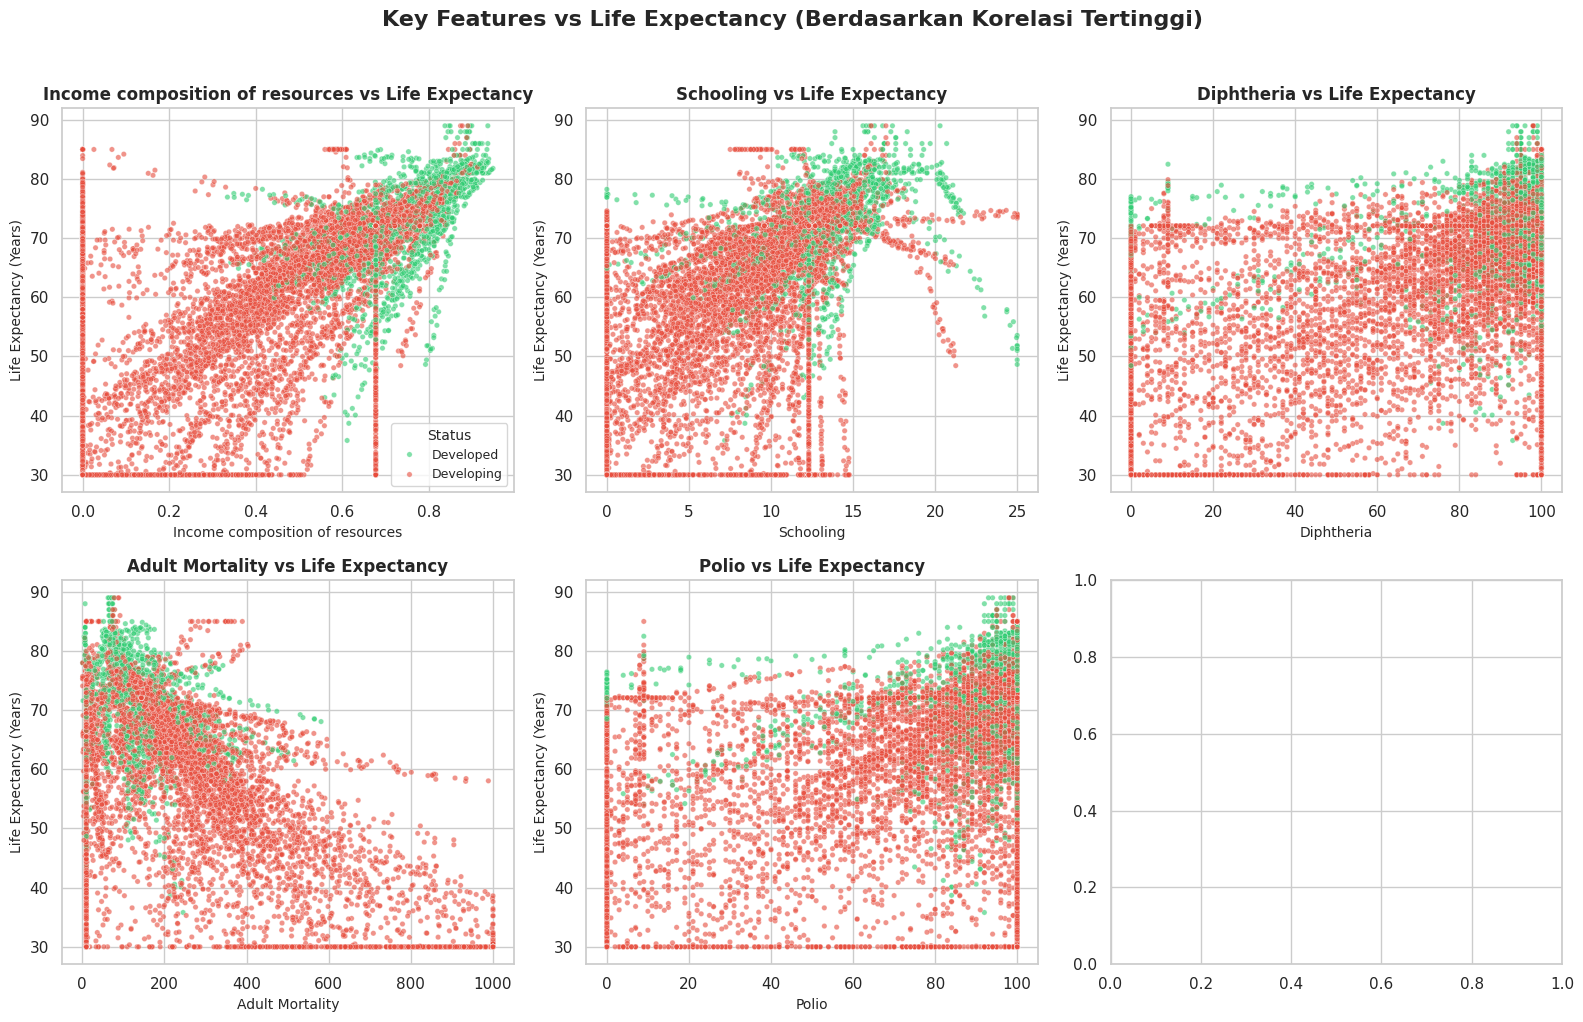

In [ ]:
# Mengupdate key_features berdasarkan hasil analisis korelasi tertinggi
key_features = [
    "Income composition of resources", # Pendorong positif terkuat 1
    "Schooling",                       # Pendorong positif terkuat 2
    "Diphtheria",                      # Pendorong positif terkuat 3
    "Adult Mortality",                 # Penarik negatif terkuat 1
    "thinness 1-19 years",             # Penarik negatif terkuat 2
    "Polio"                            # Pendorong positif terkuat 4
]

# Memastikan kolom ada di dataframe untuk mencegah error
key_features = [col for col in key_features if col in train_df.columns]

# Setup Canvas
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Pilihan warna untuk Status
palette_status = {"Developed": "#2ecc71", "Developing": "#e74c3c"}

for i, feat in enumerate(key_features):
    # Menggunakan Seaborn scatterplot agar lebih bersih dan otomatis menangani hue/legend
    sns.scatterplot(
        data=train_df,
        x=feat,
        y="Life expectancy",
        hue="Status",
        palette=palette_status,
        alpha=0.6,
        s=15,
        ax=axes[i]
    )

    axes[i].set_title(f"{feat} vs Life Expectancy", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(feat, fontsize=10)
    axes[i].set_ylabel("Life Expectancy (Years)", fontsize=10)

    # Memastikan legend hanya muncul di satu plot saja agar tidak sumpek
    if i == 0:
        axes[i].legend(title="Status", fontsize=9, title_fontsize=10)
    else:
        axes[i].get_legend().remove()

plt.suptitle("Key Features vs Life Expectancy (Berdasarkan Korelasi Tertinggi)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### 1. Pola Pengelompokan Status (Developed vs Developing)
Secara keseluruhan, warna hijau (Negara Maju / Developed) dan merah (Negara Berkembang / Developing) terpisah dengan sangat jelas:

Negara Maju (Hijau):

Selalu mengelompok rapat di zona "ideal". Yaitu di sudut kanan atas untuk fitur-fitur positif (Income, Schooling, Diphtheria, Polio) dan di sudut kiri atas untuk fitur negatif (Adult Mortality). Ini menunjukkan variansi yang rendah; standar hidup di negara maju cenderung seragam dan tinggi.

Negara Berkembang (Merah):

Titik-titiknya sangat tersebar luas (scattered). Ini mencerminkan realitas bahwa kategori "Negara Berkembang" itu sangat luas; ada yang kondisinya sudah hampir menyamai negara maju, namun banyak juga yang kondisinya sangat memprihatinkan.

#### 2. Membedah Hubungan Fitur (Korelasi Visual)
Income composition & Schooling:

Keduanya menunjukkan tren linear positif yang sangat jelas. Semakin ke kanan (semakin tinggi income/sekolah), titik-titik semakin naik (harapan hidup meningkat).

Adult Mortality:

Menunjukkan tren eksponensial negatif. Saat angka kematian dewasa naik sedikit saja dari angka 0-200, harapan hidup langsung anjlok secara drastis.

Imunisasi (Diphtheria & Polio):

Bentuk sebarannya unik (cenderung mengumpul di sebelah kanan/angka 100). Ini mengindikasikan bahwa banyak negara (baik maju maupun berkembang) yang sudah mencapai tingkat vaksinasi 80-100%, namun harapan hidup mereka tetap bervariasi. Artinya, vaksinasi yang tinggi adalah syarat dasar yang baik, tapi bukan satu-satunya penjamin umur panjang. Sebaliknya, vaksinasi yang rendah (< 60%) hampir eksklusif milik negara berkembang dengan harapan hidup rendah.

#### Ada Temuan Menarik: Bukti Visual Data "Kotor"
Ini adalah bagian terpenting dari analisis scatter plot ini. Jika diperhatikan dengan saksama, ada garis-garis lurus buatan yang tidak natural sama sekali:

Garis Horizontal Merah di Y = 30

Sesuai dugaan pada analisis distribusi target sebelumnya, ada garis lurus mendatar yang terbentuk dari titik-titik merah tepat di garis Life Expectancy = 30 di semua plot.

Artinya: Ada banyak data (khususnya dari negara berkembang) yang nilai Harapan Hidupnya dipaksa menjadi 30 secara massal, terlepas dari berapapun nilai Schooling atau Income-nya. Ini 100% adalah hasil dari imputasi (pengisian nilai kosong) yang salah pada proses sebelumnya.

Garis Vertikal di X = 0 (Pada Plot Income & Schooling):

Pada plot Income composition of resources dan Schooling, ada garis lurus vertikal dari titik-titik merah tepat di sumbu X = 0.

Artinya: Sangat mustahil sebuah negara memiliki angka partisipasi sekolah 0 tahun atau indeks income 0.0 secara harfiah. Ini menunjukkan bahwa nilai-nilai yang kosong (missing values) pada kolom Schooling dan Income kemungkinan besar diisi dengan angka 0 (Zero Imputation). Ini juga praktik yang salah dan akan merusak algoritma Machine Learning.

# EDA Question:
## Apakah masalah gizi/kekurusan pada anak dan remaja (thinness 1-19 years dan thinness 5-9 years) merupakan prediktor kuat yang berbanding lurus dengan tingginya kematian usia dewasa (Adult Mortality) di masa depan?

--- Matriks Korelasi Pearson ---


,thinness 1-19 years,thinness 5-9 years,Adult Mortality
thinness 1-19 years,1.000000,0.974034,0.309457
thinness 5-9 years,0.974034,1.000000,0.308412
Adult Mortality,0.309457,0.308412,1.000000


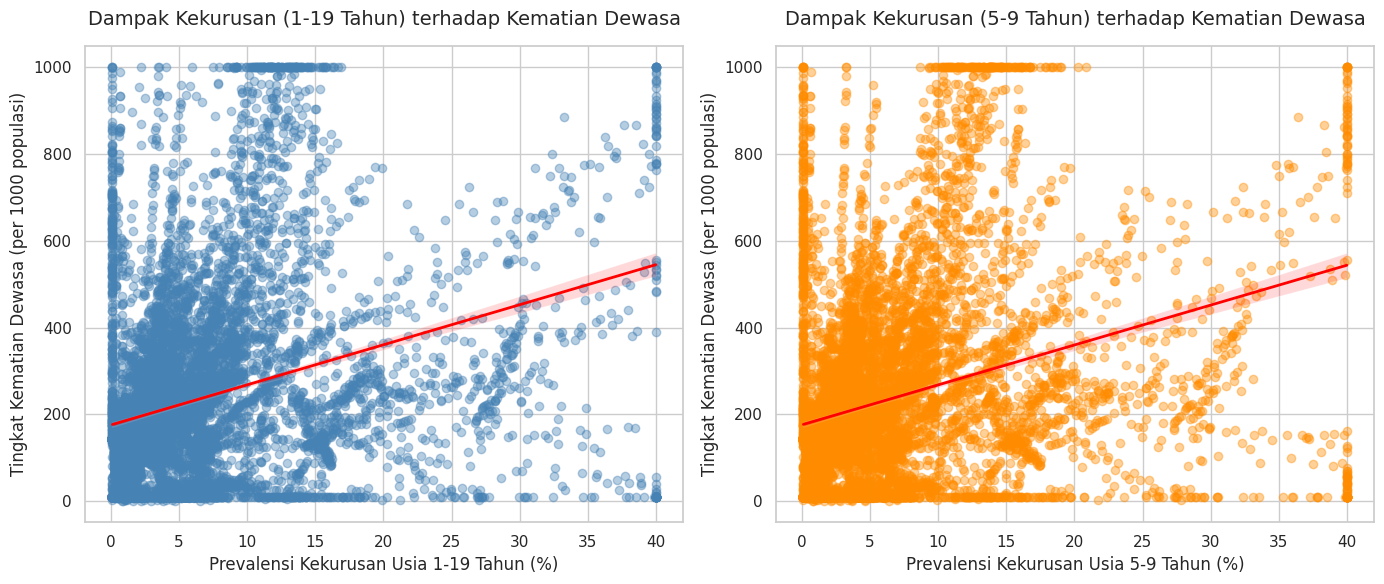

In [ ]:
cols_of_interest = ['thinness  1-19 years', 'thinness 5-9 years', 'Adult Mortality']
df_eda = train_df[cols_of_interest].dropna()

# 3. Menghitung dan menampilkan matriks korelasi
print("--- Matriks Korelasi Pearson ---")
correlation_matrix = df_eda.corr()
display(correlation_matrix)

# 4. Membuat Visualisasi (Scatter Plot dengan Garis Regresi)
# Menggunakan style seaborn agar lebih rapi
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Subplot 1: Thinness 1-19 years vs Adult Mortality
plt.subplot(1, 2, 1)
sns.regplot(data=df_eda, x='thinness  1-19 years', y='Adult Mortality',
            scatter_kws={'alpha': 0.4, 'color': 'steelblue'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title('Dampak Kekurusan (1-19 Tahun) terhadap Kematian Dewasa', fontsize=14, pad=15)
plt.xlabel('Prevalensi Kekurusan Usia 1-19 Tahun (%)', fontsize=12)
plt.ylabel('Tingkat Kematian Dewasa (per 1000 populasi)', fontsize=12)

# Subplot 2: Thinness 5-9 years vs Adult Mortality
plt.subplot(1, 2, 2)
sns.regplot(data=df_eda, x='thinness 5-9 years', y='Adult Mortality',
            scatter_kws={'alpha': 0.4, 'color': 'darkorange'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title('Dampak Kekurusan (5-9 Tahun) terhadap Kematian Dewasa', fontsize=14, pad=15)
plt.xlabel('Prevalensi Kekurusan Usia 5-9 Tahun (%)', fontsize=12)
plt.ylabel('Tingkat Kematian Dewasa (per 1000 populasi)', fontsize=12)

# Merapikan dan menampilkan plot
plt.tight_layout()
plt.show()

Berdasarkan matriks korelasi dan scatter plot yang dihasilkan, ada beberapa insight penting untuk menjawab pertanyaan tersebut:

#### 1. Arah dan Kekuatan Hubungan (Matriks Korelasi):

Terdapat korelasi positif antara tingkat kekurusan di masa kanak-kanak/remaja dengan tingkat kematian dewasa. Nilai korelasinya adalah 0.309 (untuk usia 1-19 tahun) dan 0.308 (untuk usia 5-9 tahun).

Angka 0.31 ini menunjukkan hubungan yang lemah hingga sedang. Artinya, meskipun trennya berbanding lurus (semakin banyak gizi buruk pada anak, kematian dewasa cenderung naik), kekurusan bukanlah prediktor tunggal yang paling kuat.

Catatan tambahan:

Kolom thinness 1-19 years dan thinness 5-9 years memiliki korelasi yang sangat tinggi satu sama lain (0.974). Ini sangat logis karena kedua metrik ini pada dasarnya mengukur hal yang sama di rentang usia yang tumpang tindih.

#### 2. Sebaran Data (Visualisasi Scatter Plot):

Tren Garis Regresi:

Garis merah muda pada kedua grafik secara konsisten menanjak ke atas. Ini memvalidasi angka korelasi positif tadi secara visual.

Variansi yang Tinggi:

Titik-titik data (mewakili negara-negara) terlihat sangat menyebar dan tidak menempel erat pada garis merah. Terdapat banyak negara dengan tingkat kekurusan anak yang rendah (di bawah 5%), tetapi tingkat kematian dewasanya tetap sangat tinggi (titik-titik yang berkumpul di sisi kiri atas grafik). Hal ini mengindikasikan bahwa tingginya Adult Mortality di negara-negara tersebut kemungkinan besar didorong oleh faktor dominan lain seperti wabah penyakit (misal: HIV/AIDS), perang, atau fasilitas kesehatan yang minim, bukan semata-mata karena riwayat gizi buruk.

#### Kesimpulan:
Hipotesis adanya "efek domino" terbukti benar secara statistik, di mana riwayat malnutrisi atau kekurusan di masa kecil berkontribusi memendekkan harapan hidup dan meningkatkan risiko kematian di usia dewasa. Namun, karena kekuatannya berada di level moderat, intervensi kebijakan kesehatan tidak bisa hanya fokus pada perbaikan gizi anak. Pemerintah tetap harus mengatasi faktor penyumbang kematian orang dewasa lainnya secara bersamaan untuk menekan angka Adult Mortality secara optimal.

## Step 3: Data Cleaning, Data Preprocessing, dan Feature Engineering

In [ ]:
# Data Preprocessing and Feature Engineering
def preprocess_data(df, is_train=True):
    # Buat salinan data agar data asli tidak rusak
    df_clean = df.copy()

    if is_train:
        # Menghapus target yang kosong (NaN)
        df_clean = df_clean.dropna(subset=['Life expectancy'])

        # PENANGANAN ANOMALI: Membuang baris dengan Life expectancy == 30 (Hard-capping)
        df_clean = df_clean[df_clean['Life expectancy'] != 30.0]

    # DROP KOLOM MULTIKOLINEARITAS & FITUR TIDAK RELEVAN
    # infant deaths sama persis dengan under-five deaths
    # thinness 5-9 years sama persis dengan thinness 1-19 years
    # Status dibuang karena tidak ada di data test, id dibuang karena bukan prediktor
    cols_to_drop = ['infant deaths', 'thinness 5-9 years', 'Status', 'id']
    df_clean = df_clean.drop(columns=cols_to_drop, errors='ignore')

    # --- FEATURE ENGINEERING ---
    # a. Paket Imunisasi (Rata-rata dari 3 vaksin utama)
    # Fungsi mean(axis=1) otomatis mengabaikan nilai NaN saat menghitung rata-rata
    df_clean['Immunization_Index'] = df_clean[['Polio', 'Diphtheria', 'Hepatitis B']].mean(axis=1)

    # b. Indeks Kemajuan Sosio-Ekonomi (Kombinasi Pendidikan dan Pendapatan)
    df_clean['SocioEconomic_Index'] = df_clean['Schooling'] * df_clean['Income composition of resources']

    return df_clean

In [ ]:
print(f"Shape awal train: {train_df.shape}")
train_cleaned = preprocess_data(train_df, is_train=True)
test_cleaned = preprocess_data(test_df, is_train=False)
print(f"Shape setelah Cleaning & Feature Engineering train: {train_cleaned.shape}")

Shape awal train: (10070, 22)
Shape setelah Cleaning & Feature Engineering train: (9481, 21)


In [ ]:
# Pemisahan Fitur (X) dan Target (Y)
y = train_cleaned['Life expectancy']
X = train_cleaned.drop(columns=['Life expectancy'])
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
numeric_features = X.columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Menggunakan Median untuk mengatasi Skewness
    ('scaler', StandardScaler())                   # Scaling data
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features)
])

# Menampilkan hasil transformasi sementara
X_processed = preprocessor.fit_transform(X)
print(f"\nData berhasil diproses! Bentuk matriks fitur akhir: {X_processed.shape}")


Data berhasil diproses! Bentuk matriks fitur akhir: (9481, 20)


## Step 4: Random Forest Regression Model Training dan Hyper Parameter Tuning

In [ ]:
def objective(trial):
    params = {
        # Mencari jumlah pohon dari 300 sampai 500
        'n_estimators': trial.suggest_int('n_estimators', 300, 500),

        # Kedalaman pohon diperbesar sampai 90
        'max_depth': trial.suggest_int('max_depth', 5, 90),

        # Aturan pemisahan cabang (biarkan dari 2 sampai 5)
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 5),

        # Syarat minimal daun di ujung pohon
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),

        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'bootstrap': True
        # Parameter telah di kerucutkan untuk fokus pada area yang lebih menjanjikan berdasarkan iterasi sebelumnya
    }

    # Buat model dengan parameter dari trial
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(**params, random_state=42, n_jobs=-1))
    ])

    # Cross Validation 5-fold
    score = cross_val_score(model, X, y, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    rmse = -score.mean()

    return rmse

# --- MENJALANKAN 50 TRIALS ---
study = optuna.create_study(direction='minimize')
print("Memulai optimisasi dengan Optuna...")
print("Bisa ditinggal istirahat dulu, ya!")

study.optimize(objective, n_trials=50)

print("\nOptimisasi Selesai!")
print(f"Nilai RMSE terbaik: {study.best_value:.4f}")
print("Parameter terbaik yang ditemukan:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")


Memulai optimisasi dengan Optuna...
Bisa ditinggal istirahat dulu, ya!


Asumsi:
#### 1. Data Dunia Nyata Tidak Selalu "Garis Lurus" (Non-Linearitas)
Model seperti Linear Regression berasumsi bahwa hubungan antar data berbentuk garis lurus. Misalnya: "Setiap kenaikan GDP 100 dolar, harapan hidup pasti naik 0.1 tahun".
Kenyataannya, biologi dan ekonomi tidak bekerja seperti itu. Kenaikan GDP dari negara miskin ke berkembang mungkin melonjakkan harapan hidup secara drastis, tapi kenaikan GDP di negara yang sudah maju mungkin hanya menambah harapan hidup sedikit sekali. Random Forest sangat pintar menangkap pola melengkung atau berundak (non-linear) seperti ini tanpa perlu kita program secara manual.

#### 2. Tahan Banting Terhadap "Pencilan" (Outliers)
Dalam data negara-negara di dunia, pasti ada data yang ekstrem atau aneh (outlier). Misalnya, ada negara dengan tingkat kematian bayi yang sangat tinggi akibat perang di tahun tertentu, atau negara dengan GDP yang luar biasa besar tapi populasinya kecil.
Model linear sangat mudah "rusak" atau melenceng hanya karena satu atau dua data ekstrem ini. Sebaliknya, Random Forest menggunakan aturan pemisahan berdasar ambang batas (contoh: "Apakah GDP > 5000?"), sehingga angka setinggi apa pun tidak akan merusak keseluruhan model.

#### 3. Kebal Terhadap Fitur yang Saling "Mencontek" (Multikolinearitas)
Keberadaan fitur seperti GDP dan percentage expenditure (pengeluaran kesehatan dari GDP). Secara logika, kedua fitur ini sangat berkaitan erat (jika GDP naik, pengeluaran kesehatan biasanya ikut naik).
Model statistik tradisional sering kali kebingungan dan performanya turun jika diberi dua fitur yang saling berkaitan erat. Random Forest tidak peduli dengan hal ini. Ia akan tetap menyeleksi fitur mana yang memisahkan data dengan paling baik tanpa merasa bingung.

#### 4. Bisa Memberi Tahu Fitur Mana yang Paling Penting (Feature Importance)
Setelah model selesai dilatih, kita bisa meminta model untuk mengurutkan fitur apa yang paling menentukan angka harapan hidup.
Misalnya, model bisa membuktikan bahwa Schooling (Pendidikan) dan Adult Mortality jauh lebih penting dampaknya daripada sekadar Polio atau Hepatitis B.

#### 5. Tidak Mudah "Menghafal" Data (Mencegah Overfitting)
Jika model terlalu rumit, ia cenderung "menghafal" kunci jawaban dari data train, tapi hancur saat dites menggunakan data test. Karena Random Forest membuat pohon-pohonnya secara acak (random) dari sampel data yang diacak juga, model ini sangat tangguh dan secara natural mencegah overfitting.

## Step 6: Final Model Training & Validation

In [ ]:
best_params = study.best_params
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(**study.best_params, random_state=42, n_jobs=-1))
])

print("\nMelatih model untuk validasi visualisasi...")
final_model.fit(X_train, y_train)
y_val_pred = final_model.predict(X_val)

r2  = r2_score(y_val, y_val_pred)
mse = mean_squared_error(y_val, y_val_pred)
mae = mean_absolute_error(y_val, y_val_pred)

print(f"\n--- HASIL VALIDASI PADA X_val ---")
print(f"Validation R^2  Score: {r2:.4f}")
print(f"Validation RMSE: {np.sqrt(mse):.4f}")
print(f"Validation MAE: {mae:.4f}\n")

# Plotting
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Actual vs Predicted
axes[0].scatter(y_val, y_val_pred, alpha=0.4, s=15, color="#4C72B0")
min_val = min(y_val.min(), y_val_pred.min())
max_val = max(y_val.max(), y_val_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Perfect fit")
axes[0].set_title(f"RF Actual vs Predicted (R�={r2:.4f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Actual Life Expectancy")
axes[0].set_ylabel("Predicted Life Expectancy")
axes[0].legend()

# Residuals plot
residuals = np.array(y_val) - y_val_pred
axes[1].scatter(y_val_pred, residuals, alpha=0.4, s=15, color="#DD8452")
axes[1].axhline(0, color="red", linewidth=1.5, linestyle="--")
axes[1].set_title("RF Residuals vs Predicted Values", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Life Expectancy")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

## Interpretasi

Terlihat bahwa RF berhasil dengan cukup baik memprediksi life expectancy dengan kesalahan yang cukup minim. Nampak juga semacam clustering di area prediksi 60-80 karena memang banyak negara memiliki life expectancy di area tersebut, maka akan lebih cenderung menggendut pada area tersebut

## Step 8: Predicting Test and Creating Submission

In [ ]:
test_cleaned = preprocess_data(test_df, is_train=False)

test_predictions = final_model.predict(test_cleaned)

# Membuat dataframe submission
submission = pd.DataFrame({
    'id': test_df['id'] if 'id' in test_df.columns else np.arange(len(test_predictions)),
    'Predicted_Life_Expectancy': test_predictions
})

# 4. Simpan ke CSV
submission.to_csv('submission_RandomForest_Optuna.csv', index=False)
print("\nFile 'submission_RandomForest_Optuna.csv' berhasil dibuat!")